<center><h1>Ejercicio_3</h1></center>
<center><h2>Hands-On Reinforcement Learning Applied to Trade Execution Algorithms</h2></center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/aoteog/">Oteo García, Alberto</a></cite>
</center>
<center>
Autor: <cite><a href="https://www.linkedin.com/in/jesus-sanz/">Sanz del Real, Jesús</a></cite>
</center>
<center><i>Notebook base del taller: <code>workshop/execution_lab.ipynb</code> · Réplica de <code>Ejercicio_2/Ejercicio_2.ipynb</code> · Entrega del <b>Ejercicio 3</b> (Taller de RL aplicado · MIAX, Módulo VI)</i></center>
<center><h3>Exploración guiada por el aprendizaje: un ε que no depende del número de episodios</h3></center>

----------------

## 0. Ejercicio 3 · enunciado, alcance y guía de lectura

**Enunciado (Ejercicio 3 · 1.5 puntos).** *Modifica el sistema de exploración para que el epsilon (factor de exploración) no dependa del número de episodios. Deberemos ir bajando la exploración conforme vaya mejorando el agente (i.e., mejorar resultados y/o conocer el espacio). La duración del entrenamiento debería estar condicionada a la evolución del aprendizaje; no obstante, para este ejercicio se puede mantener un número fijo de episodios.*

*Nota: hay muchas soluciones posibles; lo importante es explicar la lógica seguida, es decir, responder a* **¿cómo determinamos que el algoritmo ha mejorado?** *y* **¿cómo trasladamos esta mejora a nuestro epsilon?**

| Lo que pide el enunciado | Dónde está en este notebook |
|---|---|
| Un ε que **no dependa del número de episodios** | §3.1 (qué falla con el ε lineal) y §3.3 (el nuevo ε solo depende del progreso medido) |
| **¿Cómo determinamos que el algoritmo ha mejorado?** | §3.2 (medida de progreso: evaluación *greedy* en episodios de control, normalizada entre un *baseline* y un *benchmark*) y su verificación antes de entrenar |
| **¿Cómo trasladamos la mejora a ε?** | §3.3 (controlador de ε: objetivo en función del progreso, suavizado y asimétrico) y su respuesta ante un progreso sintético |
| Número fijo de episodios | Se mantienen los **200 episodios** del Ejercicio 2 (§3.5). La parada por aprendizaje es la Idea C del Ejercicio 4 |
| Demostrar que funciona y explicar la lógica | §3.5 (entrenamiento), §3.6 (comparación con el ε lineal, 3 semillas, validación), §3.7 (prueba de estrés con hiperparámetros malos), §3.8 (imágenes en *train*) y §4 (conclusiones) |

### Convenio para marcar los bloques

Este notebook es una **réplica del Ejercicio 2**, que es su base (mismo entorno, misma recompensa y mismos hiperparámetros). Las marcas indican el cambio **respecto al Ejercicio 2**:

| Marca | Significado |
|---|---|
| 🟢 **SIN CAMBIOS** | Bloque idéntico al del Ejercicio 2 |
| 🔧 **BLOQUE MODIFICADO** | Bloque del Ejercicio 2 que se ha cambiado. Dentro del código, las líneas tocadas llevan `# 🔧` |
| ➕ **BLOQUE AÑADIDO** | Celda nueva. En el código, las líneas nuevas dentro de un bloque modificado llevan `# ➕` |

Para no alargar el notebook, de los bloques 🟢 del Ejercicio 2 se conservan solo los que hacen falta para ejecutar (entorno, métricas, TWAP, agente). Sus explicaciones están en el notebook del Ejercicio 2.

### Decisiones generales

* **Activo y datos:** Repsol (`data/rep_data.pkl`), como en los Ejercicios 1 y 2. Se entrena con *train* (2018) y la comparación final se hace sobre *validation* (2019), igual que la selección de hiperparámetros del Ejercicio 2.
* **Lo único que cambia es la exploración.** Entorno, estado `[time_left, vol_left, lag]`, recompensa `−|ejecutado − calendario|`, Double DQN (`FastDDQNAgent`) e hiperparámetros (γ = 0.95, aprender cada 8 steps, buffer 20 000, α = 1e-3, 32 neuronas, 200 episodios) son los del Ejercicio 2. Así cualquier diferencia en los resultados se debe al esquema de ε.

### La solución en breve

| | |
|---|---|
| **¿Cómo determinamos que el agente ha mejorado?** | Cada 10 episodios se evalúa el agente *greedy* (sin exploración) en **8 episodios de control fijos**. Su coste se normaliza **en escala logarítmica entre la política aleatoria (0) y el TWAP clásico (1)**: un *baseline* y un nivel de aspiración, como proponen las diapositivas. Si no completa la orden, ese episodio cuenta como máximo 0.8 (§3.2) |
| **¿Cómo trasladamos la mejora a ε?** | `ε* = 0.05 + 0.95 · (1 − progreso)`, con suavizado asimétrico: baja deprisa (β = 0.5) y sube despacio (β = 0.2) si el agente empeora (§3.3). El valor de ε **solo depende del progreso medido**, no del número de episodios |
| **Configuración** | La del Ejercicio 2, sin cambios (γ = 0.95, aprender cada 8 steps, buffer 20 000, α = 1e-3, 32 neuronas, 200 episodios). Solo cambia la exploración |
| **Resultado con la configuración buena** (3 semillas, 100 episodios de *validation*) | Mismo agente final que con el ε lineal (100 % de órdenes completas, error de calendario 0.55 %), con **un tercio menos de exploración** (27 % frente a 42 % de acciones aleatorias). ε llega a ≤ 0.10 en el episodio ≈ 98 frente al 153 (§3.6) |
| **Resultado con una configuración mala** (hiperparámetros del Ejercicio 1) | El ε lineal deja de explorar aunque el agente no ha aprendido nada y acaba **comprando de golpe** (error 46 %). El adaptativo mantiene ε ≈ 1 mientras no hay progreso y llega a un **error del 0.89 %**. Como aún no completa las órdenes, sigue explorando (ε = 0.26) (§3.7) |

### Registro de cambios respecto al Ejercicio 2

| Nº | Bloque | Tipo | Qué se ha hecho | Por qué |
|---|---|---|---|---|
| 1 | Título | 🔧 | Título **Ejercicio_3** | Pedido |
| 2 | §0 Introducción, solución en breve y este registro | 🔧 | Enunciado del Ejercicio 3 y guía de lectura | Exigido: especificar los bloques modificados y la lógica seguida |
| 3 | §1 Imports, carga y exploración de datos | 🟢 | Sin cambios | Mismo problema y mismos datos |
| 4 | §2 `BestExecutionEnv` | 🟢 | Sin cambios (estado y recompensa del Ejercicio 2) | Solo se cambia la exploración |
| 5 | §2 Métricas, `TWAP`, `evaluate` y políticas de referencia | 🟢 | Sin cambios | Las políticas de referencia son las **anclas** de la medida de progreso |
| 6 | §2 `FastDDQNAgent` | 🟢 | Sin cambios | Mismo agente |
| 7 | §3.2 `preserve_rng` y `ProgressMonitor` | ➕ | Medida de progreso: evaluación *greedy* en episodios de control, normalizada entre la política aleatoria (0) y el TWAP (1) | Responde a *«¿cómo determinamos que el algoritmo ha mejorado?»* |
| 8 | §3.2 Verificación de la medida | ➕ | Progreso de las políticas de referencia y comprobación de que medir no altera el entrenamiento | Validar la medida antes de usarla |
| 9 | §3.3 `AdaptiveEpsilon` | ➕ | Controlador: ε objetivo en función del progreso, suavizado y asimétrico (baja rápido, sube despacio) | Responde a *«¿cómo trasladamos esta mejora a nuestro epsilon?»* |
| 10 | §3.4 `train_agent` | 🔧 | ε ya no baja un tanto fijo por episodio: cada `eval_every` episodios se mide el progreso y el controlador fija ε. Se conserva el esquema lineal como opción (`eps_schedule="linear"`) para comparar | Es el cambio que pide el ejercicio |
| 11 | §3.4 `run_summary`, `plot_training` | ➕ / 🔧 | Métricas de exploración (episodio en que se alcanza el objetivo, % de acciones aleatorias) y gráficos de ε frente al progreso | Mostrar la relación entre aprendizaje y exploración |
| 12 | §3.5–§3.8 Experimentos | ➕ | Entrenamiento, comparación con el ε lineal (3 semillas), prueba de estrés e imágenes | Demostrar que funciona |
| 13 | §4 Conclusiones | 🔧 | Resumen, interpretación y límites | Motivación exigida por el enunciado |

<center><h1>Resumen</h1></center>

<center>

<p style="width:80%">
    En este notebook se presenta el taller de aprendizaje por refuerzo aplicado a un caso real para finanzas. 
    El objetivo es plantear, desde cero, la resolución del problema de <b>algoritmos de ejecución</b> a través del uso
    de técnicas de aprendizaje por refuerzo. Para ello, durante el taller se ha de completar el entorno básico <b>BestExecutionEnv</b> donde los asistentes desarrollarán las partes claves del
    código para obtener un simulador de mercado que, aunque relativamente naive, será funcional. Posteriormente, los participantes tendrán que aplicar algoritmos clásicos y basados en inteligencia artificial (IA) para la
    resolución del problema. 
</p>
<p style="width:80%">
    En términos sencillos, el problema de <b>algoritmos de ejecución</b> trata sobre la ejecución de órdenes con un tamaño lo suficientemente grande como para que su ejecución suponga un <b><i>'problema'</i></b>, como se ha comentado durante la explicación del caso práctico. La resolución de la ejecución de estas órdenes (órdenes CARE) se puede realizar utilizando diferentes aproximaciones. En el caso de este taller, queremos optimizar el <b><i>timing</i></b> de nuestras órdenes para minimizar el impacto de mercado. Es decir, buscaremos trocear la orden CARE para comprar (vender) a los menores (mayores) precios de la sesión en la que se ejecuta la orden CARE. Como baseline para saber si nuestra ejecución es buena, o mala, utilizaremos el baseline habitual en el sector: el VWAP slippage.
</p> 
<p style="width:80%">
El VWAP slippage es la desviación, en puntos básicos, del VWAP del mercado en comparación con el VWAP de nuestro algoritmo. Siendo el VWAP el precio medio ponderado por el volumen:
</p>   
    
$$\frac{\sum_{i=1}^T p_i\cdot v_i}{\sum_{i=1}^Tv_i}$$

</center>

---

<center><h1>Datos</h1></center>

<center>
<p style="width:80%">
Los datos para este taller se han extraído de los activos Repsol y Santander (<i>rep_data.pkl</i> y <i>san_data.pkl</i>). Entre la información extraída contamos con la primera posición del libro de órdenes, tanto del bid como del ask, así como el volumen acumulado, todo ello realizando una agrupación por 5 segundos. Las sesiones extraidas del libro de órdenes están comprendidas entre las 13:00h y las 17:25h. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 60 días hábiles de 2018</p>
    <p style="width:35%"><b>Validación</b>: Primeros 30 días hábiles de 2019</p>
    <p style="width:35%"><b>Test</b>: Intervalo de los días hábiles del 31 al 60 de 2019 (30 días)</p>
</center>

<center>
<p style="width:80%">
<b>Adicionalmente</b>, para aquellos que quieran aumentar el grado de detalle, se han añadido otros dos ficheros con información más completa del libro de órdenes y de las ejecuciones de mercado. El fichero <i>orderbook.pkl</i> contiene las posiciones (precios y volúmenes) de hasta la tercera posición del libro de órdenes, agrupados por 5 segundos; el fichero <i>executions.pkl</i> todas las ejecuciones del mercado. En ambos casos, se trata de información para la compañía Repsol, entre las 13:00h y 17:25h de la sesión. El conjunto de datos está partido en 3 subconjuntos, para los siguientes días bursátiles:
</p>
    
</center> 
<center>
    <p style="width:35%"><b>Train</b>: Primeros 40 días hábiles de 2019</p>
    <p style="width:35%"><b>Validación</b>: Intervalo del 41 al 60 de 2019 (20 días)</p>
    <p style="width:35%"><b>Test</b>: Intervalo del 61 al 80 de 2019 (20 días)</p>
</center>

---
## 1. Preparación del entorno de trabajo y de los datos

> 🟢 **SIN CAMBIOS** — imports, cargador de los `.pkl` y exploración idénticos a los del Ejercicio 2 (y del Ejercicio 1).

### 1.1 Imports

In [1]:
import os
# Solo cosmético, y debe ir ANTES de importar TensorFlow: silencia los avisos informativos de oneDNN/TF.
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import pickle
import random
import sys
import warnings
from pathlib import Path
from typing import Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Aviso de numpy al deserializar los .pkl antiguos (numpy.core -> numpy._core). Es inocuo.
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Localiza la raíz del repo (la carpeta que contiene src/ y data/) esté donde esté el notebook.
#    Sustituye al `sys.path.append("..")` comentado del original y evita depender del directorio de trabajo.
def find_repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        for cand in (p, p / "best-execution"):
            if (cand / "src" / "agents" / "dqn.py").exists():
                return cand
    raise FileNotFoundError("No se encuentra la raíz del repo (carpeta con src/agents/dqn.py)")

REPO_ROOT = find_repo_root()
sys.path.append(str(REPO_ROOT))

from src.agents.dqn import DDQNAgent
from src.report.report import plot_results

# Reproducibilidad
import tensorflow as tf
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.get_logger().setLevel("ERROR")   # cosmético: sin el aviso de «GPU no disponible en Windows nativo»

print(f"Raíz del repo : {REPO_ROOT}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | TensorFlow {tf.__version__}")

Raíz del repo : C:\Users\inevado\Desktop\Escritorio\Ivan\venv\MIAX\PRÁCTICA RL APLICADA\TALLER_APLICACION_RL\best-execution
Python 3.10.6 | numpy 2.2.6 | pandas 2.3.2 | TensorFlow 2.21.0


### 1.2 Carga de datos

In [2]:
# Datos disponibles: san_data.pkl y rep_data.pkl
# Carga compatible con pandas 1.x y 2.x
from pandas._libs.internals import BlockPlacement
import pandas.core.internals.blocks as pd_blocks


class _CompatUnpickler(pickle.Unpickler):
    """Deserializa .pkl creados con pandas 1.x en pandas >= 2.1."""

    def find_class(self, module, name):
        if module == "pandas.core.internals.blocks" and name == "new_block":
            def _new_block(values, placement, ndim=None, *args, **kwargs):
                if not isinstance(placement, BlockPlacement):
                    placement = BlockPlacement(placement)
                return pd_blocks.new_block(values, placement, ndim=ndim, *args, **kwargs)
            return _new_block
        return super().find_class(module, name)


def load_pickle_compat(path):
    try:
        with open(path, "rb") as f:
            return pickle.load(f)                   # camino normal (el del original)
    except TypeError:
        with open(path, "rb") as f:
            return _CompatUnpickler(f).load()       # fallback para pandas >= 2.1


dict_ = load_pickle_compat(REPO_ROOT / "data" / "rep_data.pkl")
dict_.keys()

dict_keys(['train', 'val', 'test'])

### 1.3 Exploración de los datos

In [3]:
data = dict_["train"]   # línea original: el entorno se entrena con los 60 días de train (2018)

# Resumen legible en lugar de volcar el diccionario completo
days = list(data.keys())
print(f"train: {len(days)} días ({days[0]} → {days[-1]}) | columnas: {list(data[days[0]].columns)}")
display(data[days[0]].head())


def resumen_split(split: dict) -> dict:
    dfs = list(split.values())
    spread_bps = pd.concat([(d["ask1"] - d["bid1"]) / ((d["ask1"] + d["bid1"]) / 2) * 1e4 for d in dfs])
    vol = pd.concat([d["cumvol"].diff().dropna() for d in dfs])
    vol_pos = vol.clip(lower=0)
    top1 = vol_pos.sort_values(ascending=False).head(int(len(vol_pos) * 0.01)).sum() / vol_pos.sum()
    return {
        "días": len(dfs),
        "bins por día (mín–máx)": f"{min(map(len, dfs))}–{max(map(len, dfs))}",
        "spread medio (bps)": round(spread_bps.mean(), 2),
        "volumen medio por bin (títulos)": round(vol.mean()),
        "% de bins sin volumen": round((vol == 0).mean() * 100, 1),
        "% del volumen en el 1 % de bins": round(top1 * 100, 1),
        "incrementos negativos de cumvol": int((vol < 0).sum()),
    }


display(pd.DataFrame({name: resumen_split(split) for name, split in dict_.items()}))

train: 60 días (2018-01-02 → 2018-03-26) | columnas: ['ask1', 'bid1', 'vask1', 'vbid1', 'last', 'cumvol', 'date']


,ask1,bid1,vask1,vbid1,last,cumvol,date
time,,,,,,,
2018-01-02 13:00:00,15.00,14.995,1368.0,1878.0,15.000,1429424.0,2018-01-02
2018-01-02 13:00:05,15.01,15.005,1308.0,1.0,15.000,1430792.0,2018-01-02
2018-01-02 13:00:10,15.01,15.000,2988.0,5438.0,15.005,1431776.0,2018-01-02
2018-01-02 13:00:15,15.01,15.000,2158.0,7941.0,15.005,1431776.0,2018-01-02
2018-01-02 13:00:20,15.01,15.000,2138.0,10009.0,15.005,1431978.0,2018-01-02


,train,val,test
días,60,30,30
bins por día (mín–máx),3177–3181,3179–3181,3179–3181
spread medio (bps),4.68,4.29,4.12
volumen medio por bin (títulos),1002,1047,738
% de bins sin volumen,76.3,77.1,82.1
% del volumen en el 1 % de bins,64.5,66.6,68.6
incrementos negativos de cumvol,2,0,0


---
## 2. Entorno, métricas y agente del Ejercicio 2

> 🟢 **SIN CAMBIOS** — esta sección reúne, sin tocarlos, los bloques del Ejercicio 2 que hacen falta para entrenar: el entorno con el estado y la recompensa del TWAP, las métricas de fidelidad al calendario (C1–C5), el TWAP del Ejercicio 1 como *benchmark* y el `FastDDQNAgent`. Su diseño y justificación están en el notebook del Ejercicio 2 (§2.2–§2.6).

Recordatorio de lo que importa para este ejercicio:

* **Recompensa:** `r_t = −|ejecutado − calendario lineal|` (en títulos) más una recompensa final. Por tanto **coste = −retorno = desviación acumulada respecto al calendario**: cuanto menor, mejor.
* **Criterios** (§2.1 del Ejercicio 2): C1 completar la orden, C2 usar casi todo el tiempo, C3 error de seguimiento (`mae_pct`, % de la orden; mínimo teórico ≈ 0.5 %), C4 compras equiespaciadas, C5 *slippage* igual al del TWAP.
* **Políticas de referencia:** aleatoria, «no comprar nunca», «comprar de golpe», el TWAP del Ejercicio 1 y la regla óptima `lag > ½`, demostrada por programación dinámica en el Ejercicio 2.

> 🟢 **SIN CAMBIOS** — `BestExecutionEnv` del Ejercicio 2 (estado `[time_left, vol_left, lag]`, recompensa `−|ejecutado − calendario|` y recompensa final).

In [4]:
class BestExecutionEnv:

    # ➕ El retraso respecto al calendario que ve el agente se recorta a ±5 órdenes hijas (ver observation_builder)
    LAG_CLIP = 5.0

    def __init__(self, data, look_back=60, state_mode="schedule"):  # 🔧 nuevo argumento state_mode
        """Inicialización de la clase del entorno que simula
        el libro de ordenes.
        ----------------------------------------------------
        Input:
            - data:
                Dataframe con los datos previamente
                agrupados del libro de órdenes.

            - look_back:
                Ventana para la generación de features
                roladas en el instante t=0 del episodio.
                Esta ventana representa el rango máximo para
                la construcción de features.

            - state_mode:   (➕ Ejercicio 2)
                "basic":    estado del Ejercicio 1 -> [time_left, vol_left]
                "schedule": basic + retraso respecto al calendario lineal
                            -> [time_left, vol_left, lag]
        ----------------------------------------------------
        Variables Internas:
            - episode_bins:
                Número de bines (steps) del episodio.
            - episode_full_len:
                Es igual a look_back + episode_bins.
            - vol_care:
                Volumen total (en títulos) de la orden care.
            - actions_fn:
                Diccionario con las posibles acciones del agente.
                Las claves acceden a la función que evalúa la acción
                tomada por el agente.
            - n_actions:
                Número de acciones posibles.
            - n_features:
                Número de características de los estados.
            - episode:
                Dataframe que contiene los steps y estados del episodio.
            - episode_full:
                Es el episode añadiendo el look_back antes del comienzo
                del episodio.
            - episode_vwap:
                VWAP de mercado al final del episodio.
            - market_ep_vol:
                Volumen (títulos) ejecutado por el mercado en cada bin del episodio.
            - state_pos:
                Número de step en el que nos encontramos.
            - exec_vol:
                Acumulado de títulos ejecutados por el algoritmo.
            - actions_hist:
                Lista de acciones tomadas por el algoritmo en cada step.
            - market_vwap_hist:
                Lista de VWAP de mercado en cada step.
            - reward_hist:
                Lista de rewards obtenidas en cada step.
            - price_hist:
                Lista de precios ejecutados en cada step.
            - vol_hist:
                Lista de títulos ejecutados en cada step.
        """

        # Fixed params
        self.data = data
        self.look_back = look_back
        assert state_mode in ("basic", "schedule")   # ➕ debe fijarse antes de _detect_num_feat()
        self.state_mode = state_mode                 # ➕
        self.episode_bins = None
        self.episode_full_len = None
        self.vol_care = None

        self.actions_fn = {
            0: self._do_nothing,
            1: self._agg_action,
        }

        self.n_actions = len(self.actions_fn)
        self.n_features = self._detect_num_feat()

        # Data variables
        self.episode = None
        self.episode_full = None

        # Env variables
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _detect_num_feat(self):
        """Detecta el número de variables del estado.
        Función necesaria para adaptarse automaticamente a los
        cambios en las variables de observation_builder.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        s = self.observation_builder()
        return s.shape[0]

    def _reset_env_episode_params(self):
        """
        Reset del episodio e inicialización de los parámetros.
        Las variables internas vuelven a sus valores originales.
        """
        self.episode_full_len = None
        self.episode = None
        self.episode_full = None
        self.episode_vwap = None
        self.market_ep_vol = None
        self.state_pos = 0
        self.algo_vwap = 0
        self.exec_vol = 0
        self.actions_hist = []
        self.algo_vwap_hist = []
        self.market_vwap_hist = []
        self.reward_hist = []
        self.price_hist = []
        self.vol_hist = []

    def _generate_episode_params(self):
        """(1) Se determinan las características de la orden a ejecutar.
        La orden queda definida por:
         - episode_bins:
             Obtención de un número entero aleatorio [400, 600]
             con una distribución uniforme.
         - vol_care:
             Obtención del porcentaje de steps en el que hay que
             ejecutar una orden para cubrir la orden care.
             vol_care responde a un valor uniforme [0.075, 0.125]
             multiplicado por el número self.episode_bins.
             Lo convertimos a entero.
        """
        # Int aleatorio entre 400 y 600 (ambos incluidos) como un objeto numpy.
        #    np.random.randint excluye el extremo superior -> 601.
        self.episode_bins = np.random.randint(400, 601)
        # Float aleatorio uniforme entre 0.075 y 0.125 (fracción de steps en los que hay que comprar)
        pct_bins = np.random.uniform(0.075, 0.125)
        # Tamaño de la orden CARE en títulos = pct_bins * episode_bins, truncado a int
        #    (órdenes hijas de 1 título -> vol_care = nº de acciones agresivas necesarias)
        self.vol_care = int(pct_bins * self.episode_bins)

        self.episode_full_len = self.episode_bins + self.look_back

        assert self.episode_bins <= 600
        assert self.episode_bins >= 400
        assert self.vol_care <= int(self.episode_bins * 0.125)
        assert self.vol_care >= int(self.episode_bins * 0.075)
        assert isinstance(self.vol_care, int)

    def _generate_episode(self):
        """(2) Obtenemos el día y hora en el que comienza el episodio.
        """
        self._generate_episode_params()

        length_episode = 0
        while length_episode != self.episode_full_len:
            # Selección de un día al azar entre los disponibles (las keys de data son fechas)
            selected_day = np.random.choice(list(self.data.keys()))

            # Extraemos el DataFrame de ese día
            data_day = self.data[selected_day]

            # Hora de inicio aleatoria: una marca temporal cualquiera del índice del día
            init_time = np.random.choice(data_day.index)

            hour_pos = data_day.index.get_loc(init_time)
            initial_position = hour_pos - self.look_back
            final_position = hour_pos + self.episode_bins

            if initial_position < 0:
                continue
            else:
                # episode_full: look_back bins previos + los episode_bins del episodio.
                #    Si final_position se sale del día, el slice queda más corto y el
                #    while vuelve a muestrear (resample) otro día/hora.
                self.episode_full = data_day.iloc[initial_position:final_position]

                # episode: solo los bins del episodio (desde hour_pos)
                self.episode = data_day.iloc[hour_pos:final_position]

                length_episode = self.episode_full.shape[0]


    def reset(self) -> np.array:
        """Reinicialización del episodio junto con los parámetros.
        Devuelve la primera observación del nuevo episodio.
        """
        self._reset_env_episode_params()
        self._generate_episode()
        self._compute_episode_market_feat()

        return self.observation_builder()

    def observation_builder(self) -> np.array:
        """(3) Función para la construcción de las observaciones del estado.
            ------------------------------------------------------------
            Ejercicio 2:
                - Primera característica es tiempo restante en porcentaje.
                - Segunda característica es el volumen restante en porcentaje.
                - Tercera característica (state_mode="schedule"): retraso respecto
                  al calendario lineal, medido en órdenes hijas.
        """
        time_left = (self.episode_bins - self.state_pos) / self.episode_bins
        vol_left = (self.vol_care - self.exec_vol) / self.vol_care
        if self.state_mode == "basic":
            return np.array([time_left, vol_left])

        # 🔧 Retraso (lag) = títulos que el calendario lineal exige llevar al terminar ESTE step menos los que ya
        #    llevamos comprados. lag > 0: vamos por detrás del calendario · lag < 0: por delante.
        #    Se mide en órdenes hijas (1 título), de modo que no depende del tamaño de la orden ni de la duración
        #    del episodio, y se recorta a ±LAG_CLIP y se escala a [-1, 1]: más allá de ese rango la decisión óptima
        #    ya es obvia (comprar si vamos muy por detrás, esperar si vamos muy por delante).
        lag = self.vol_care * (self.state_pos + 1) / self.episode_bins - self.exec_vol
        lag_feat = float(np.clip(lag / self.LAG_CLIP, -1.0, 1.0))
        obs = np.array([time_left, vol_left, lag_feat])

        return obs

    def _compute_episode_market_feat(self) -> Tuple[float, pd.Series]:
        """(4) Cálculo de los valores VWAP y Market Vol del episodio.
        Como no tenemos las ejecuciones de mercado, asumimos que el
        precio es el mid price de cada step.
        """
        # Mid price de cada bin
        mid = (self.episode["ask1"] + self.episode["bid1"]) / 2
        # Volumen del mercado en cada bin = incremento del volumen acumulado.
        #    Se recorta a 0 por calidad de datos: hay (muy pocos) incrementos negativos
        #    en train (correcciones del volumen acumulado) que no tienen sentido como volumen.
        self.market_ep_vol = self.episode["cumvol"].diff().clip(lower=0)
        self.market_ep_vol.iloc[0] = 0
        # Volumen total negociado por el mercado en el episodio
        cum_vol = self.market_ep_vol.sum()
        # VWAP del episodio: el mid de cada bin t se pondera con el volumen negociado
        #    justo después (bin t+1). .values para que pandas no alinee por índice.
        if cum_vol == 0:
            # Episodio sin ningún volumen de mercado: VWAP indefinido -> usamos el mid medio
            self.episode_vwap = mid.mean()
        else:
            self.episode_vwap = (mid.values[:-1] * self.market_ep_vol.values[1:]).sum() / cum_vol

        return self.episode_vwap, self.market_ep_vol

    def _compute_algo_vwap(self) -> float:
        """(8) Cálculo del VWAP del algoritmo hasta el step actual.
        """
        # VWAP del algoritmo = sum(precio * volumen) / sum(volumen) con lo ejecutado hasta ahora
        p_arr = np.array(self.price_hist)
        v_arr = np.array(self.vol_hist)
        if v_arr.sum() == 0:
            # Todavía no hemos ejecutado nada: el VWAP no está definido
            # (NaN -> stats_df hace ffill y el gráfico no dibuja nada hasta la primera ejecución)
            return np.nan
        algo_vwap = (p_arr * v_arr).sum() / v_arr.sum()
        return algo_vwap

    def _compute_reward(self, price: float, vol: float) -> float:
        """(6) Función de diseño de los rewards y penalizaciones que
        recibe el algoritmo al tomar las acciones.
        --------------------------------------------------------
        Ejercicio 2 (replicar un TWAP):
            - El reward es MENOS el valor absoluto de la desviación, en títulos, entre lo
              ejecutado y el calendario lineal (TWAP) tras la acción. No usa el precio.
        """
        # 🔧 Calendario lineal: al terminar este step (state_pos todavía no se ha incrementado) el TWAP
        #    llevaría vol_care * (state_pos + 1) / episode_bins títulos. `exec_vol` ya incluye la acción actual.
        #    Un TWAP es un calendario independiente del precio -> `price` y `vol` no intervienen.
        scheduled = self.vol_care * (self.state_pos + 1) / self.episode_bins
        deviation = self.exec_vol - scheduled           # > 0 por delante · < 0 por detrás (en títulos)
        reward = -abs(deviation)
        return reward

    def _compute_stop_conditions(self) -> Tuple[bool, bool]:
        """(10) Define las condiciones de parada del episodio
        Return:
            Tiempo agotado, orden completada
        """
        # Tiempo agotado: ya hemos consumido todos los bins del episodio
        is_bins_complete = self.state_pos >= self.episode_bins
        # Orden completada: ya hemos comprado (al menos) todo el volumen de la orden CARE
        is_ord_complete = self.exec_vol >= self.vol_care
        return is_bins_complete, is_ord_complete

    def _compute_done_reward(self) -> float:
        """(12) Recompensa al terminar el episodio.
        Ejercicio 2: si la orden se completa antes de agotar el tiempo, el calendario "sigue corriendo":
        se carga la desviación que se habría acumulado en los steps que quedan por jugar.
        """
        # 🔧 Así el coste de un episodio es la suma de |desviación| a lo largo de TODOS sus steps, termine
        #    cuando termine: completar la orden antes de tiempo no sirve para "escapar" de las penalizaciones
        #    (sin este término el óptimo sería terminar unos steps antes que el TWAP, ver §2.5).
        #    state_pos ya se ha incrementado: los steps sin jugar son state_pos, ..., episode_bins - 1.
        #    Si el tiempo se ha agotado la lista está vacía y la recompensa final vale 0.
        remaining = np.arange(self.state_pos, self.episode_bins)
        scheduled = self.vol_care * (remaining + 1) / self.episode_bins
        done_reward = -float(np.sum(np.abs(self.exec_vol - scheduled)))
        return done_reward

    def _agg_action(self) -> float:
        """(7) Acción agresiva de compra de un título a precio de episode['ask1'].
        Devolvemos el reward asociado a esa acción.
        """
        # Precio de la acción agresiva: ask1 del bin actual (acceso posicional por state_pos)
        price = self.episode["ask1"].iloc[self.state_pos]
        # Registramos precio y volumen (1 título) y actualizamos el volumen ejecutado
        self.price_hist.append(price)
        vol = 1
        self.exec_vol += vol
        self.vol_hist.append(vol)

        # VWAP del algoritmo tras esta ejecución, guardado en su histórico
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        # Reward asociado a esta ejecución
        reward = self._compute_reward(price, vol)
        return reward

    def _do_nothing(self) -> float:
        """(9) No hacer nada y devolvemos el reward asociado a la acción
        """
        # Mismo proceso que _agg_action pero con precio y volumen ejecutado = 0
        price = 0
        vol = 0
        self.price_hist.append(price)
        self.vol_hist.append(vol)
        algo_vwap = self._compute_algo_vwap()
        self.algo_vwap_hist.append(algo_vwap)
        reward = self._compute_reward(price, vol)

        return reward

    def _compute_market_vwap(self) -> float:
        """(5) Cálculo del VWAP del mercado hasta el step actual.
        """
        # Mismo criterio que en _compute_episode_market_feat: precio = mid de cada step...
        mid_p = (self.episode["ask1"] + self.episode["bid1"]) / 2
        mkt_p = mid_p
        # ...y volumen = el negociado en el bin siguiente (shift(-1)). El último step no tiene
        # bin siguiente -> fillna(0) (si no, el NaN contaminaría todas las sumas).
        v = self.market_ep_vol.shift(-1).fillna(0)
        # VWAP del mercado acumulado hasta el step actual (incluido)
        p_arr = mkt_p.values[:self.state_pos + 1]
        v_arr = v.values[:self.state_pos + 1]
        sum_vol = v_arr.sum()
        # Si el mkt vol hasta el step == 0, devolvemos el último precio hasta el step
        if sum_vol == 0:
            return p_arr[-1]
        # VWAP acumulado hasta el step
        market_vwap = (p_arr * v_arr).sum() / sum_vol
        return market_vwap

    def _compute_done(self) -> bool:
        """(11) Reglas de finalización del episodio.
        """
        # Terminamos si se agota el tiempo o si se completa la orden (cualquiera de las dos)
        conditions = self._compute_stop_conditions()
        is_bins_complete, is_ord_complete = conditions
        done = is_bins_complete or is_ord_complete
        return done

    def step(self, action) -> Tuple[np.array, float, bool, dict]:
        """ Evalúa la acción, calcula la recompensa, devuelve el
        nuevo estado y si el episodio ha terminado.
        """
        market_vwap = self._compute_market_vwap()

        act_fn = self.actions_fn.get(action)
        if act_fn is None:
            raise ValueError(
                f"Invalid action {action}. Valid actions {self.actions_fn.keys()}"
            )

        reward = act_fn()

        # Guardamos la acción tomada (actions_hist estaba documentada pero nunca se rellenaba)
        self.actions_hist.append(action)
        self.market_vwap_hist.append(market_vwap)
        self.reward_hist.append(reward)

        self.state_pos += 1

        done = self._compute_done()

        if done:
            done_reward = self._compute_done_reward()
            reward += done_reward
            self.reward_hist[-1] += done_reward   # ➕ reward_hist recoge así el retorno completo del episodio
            return None, reward, done, {}

        observation = self.observation_builder()

        return np.array(observation), reward, done, {}

    def action_sample(self) -> int:
        """(13) Devuelve una acción aleatoria. El valor ha de corresponder
        con las keys de actions_fn.
        """
        # Política aleatoria SESGADA hacia no hacer nada: comprar con probabilidad p igual a
        #    la participación que necesita la orden (vol_care / episode_bins ~ 7.5%-12.5%).
        #    Con p = 0.5 la orden se completaría en ~2*vol_care steps (~20% del episodio) y el
        #    buffer solo contendría estados con mucho tiempo restante; con p ~ vol_care/bins el
        #    comportamiento aleatorio recorre todo el episodio (time_left de 1 a 0).
        p = self.vol_care / self.episode_bins
        action = np.random.choice([0, 1], p=[1-p, p])
        return action

    def stats_df(self):
        """Información para el gráfico de resultados de la ejecución
        """

        my_df = pd.DataFrame(
            {"vwap": self.algo_vwap_hist, "vol": self.vol_hist},
            index=list(self.episode.index)[:len(self.algo_vwap_hist)]
        )
        my_df = my_df.reindex(self.episode.index)
        my_df["vol"] = my_df["vol"].fillna(0)
        my_df["vwap"] = my_df["vwap"].ffill()


        p = self.episode["ask1"]
        v = self.episode["cumvol"].diff().shift(-1)
        last_v = self.episode_full["cumvol"].diff().iloc[-1]
        v.iloc[-1] = last_v
        market_vwap = (p * v).cumsum() / v.cumsum()
        market_df = pd.DataFrame(
            {"vwap": market_vwap, "vol": v},
            index=v.index
        )

        mpx = (self.episode["ask1"] + self.episode["bid1"]) / 2

        return my_df, market_df, mpx

> 🟢 **SIN CAMBIOS** — métricas C1–C5 (`episode_metrics`, `summarize`), TWAP del Ejercicio 1, `run_episode`, `evaluate` y tabla de políticas de referencia del Ejercicio 2. Las usaremos como **anclas** de la medida de progreso.

In [5]:
def episode_metrics(env) -> dict:
    """Métricas de un episodio TERMINADO (se llamó a env.step hasta done).
    slippage_bps = (VWAP algo - VWAP mercado) / VWAP mercado * 1e4  ->  en una compra, negativo = mejor que el mercado.
    🔧 Nuevas (fidelidad al calendario lineal de un TWAP):
        mae_pct : error de seguimiento medio |ejecutado - calendario| en % de la orden        (criterio C3)
        max_dev : desvío máximo respecto al calendario, en títulos
        gap_cv  : coeficiente de variación de la separación entre compras consecutivas        (criterio C4)
    """
    prices = np.array(env.price_hist, dtype=float)
    vols = np.array(env.vol_hist, dtype=float)
    exec_vol = vols.sum()
    algo_vwap = (prices * vols).sum() / exec_vol if exec_vol > 0 else np.nan
    B, C, steps = env.episode_bins, env.vol_care, env.state_pos
    dev = np.cumsum(vols) - C * np.arange(1, steps + 1) / B          # ➕ desviación respecto al calendario tras cada step
    gaps = np.diff(np.flatnonzero(env.actions_hist))                 # ➕ separación entre compras (en steps)
    return {
        "bins": B, "vol_care": C, "steps": steps,
        "exec_frac": exec_vol / C, "time_frac": steps / B,
        "algo_vwap": algo_vwap, "mkt_vwap": env.episode_vwap,
        "slippage_bps": (algo_vwap - env.episode_vwap) / env.episode_vwap * 1e4,
        "sum_reward": float(np.sum(env.reward_hist)),
        "mae_pct": float(np.abs(dev).mean() / C * 100),              # ➕
        "max_dev": float(np.abs(dev).max()),                         # ➕
        "gap_cv": float(gaps.std() / gaps.mean()) if len(gaps) > 2 else np.nan,   # ➕
    }


class TWAP(DDQNAgent):
    def act(self, s): # [T, V, lag]
        # TWAP determinista a partir del estado: calendario lineal (ver Ejercicio 1).
        # Compramos siempre que vayamos igual o por detrás de ese calendario, es decir, cuando V >= T.
        T, V = s[0], s[1]       # 🔧 el estado ahora tiene 3 variables; solo se usan las dos primeras
        a = int(V >= T - 1e-9)
        return a


def run_episode(env, policy):
    s, done = env.reset(), False
    while not done:
        s, r, done, _ = env.step(policy(s))
    return episode_metrics(env)


def evaluate(env, policy, n_episodes=40, seed0=10_000):
    rows = []
    for i in range(n_episodes):
        np.random.seed(seed0 + i)       # mismo episodio para todas las políticas
        rows.append(run_episode(env, policy))
    return pd.DataFrame(rows)


def summarize(df):
    # 🔧 Una fila por criterio de §2.1 (C1–C5) más el retorno
    return pd.Series({
        "C1 · órdenes completas (%)": (df.exec_frac >= 1).mean() * 100,
        "volumen ejecutado (% de la orden)": df.exec_frac.mean() * 100,
        "C2 · tiempo usado (% del episodio)": df.time_frac.mean() * 100,
        "C3 · error de seguimiento (% de la orden)": df.mae_pct.mean(),
        "desvío máximo (títulos)": df.max_dev.mean(),
        "C4 · CV de la separación entre compras": df.gap_cv.mean(),
        "C5 · slippage vs VWAP (bps) · media": df.slippage_bps.mean(),
        "retorno (suma de rewards) · media": df.sum_reward.mean(),
    })


N_EVAL = 40     # ➕ episodios por evaluación (los mismos para todas las políticas)

env_pol = BestExecutionEnv(dict_["train"], 60)
twap = TWAP(env_pol)
policies = {
    "TWAP (Ej. 1)": twap.act,
    "Regla lag > ½": lambda s: int(s[2] * env_pol.LAG_CLIP > 0.5),
    "Aleatoria": lambda s: env_pol.action_sample(),
    "Comprar de golpe": lambda s: 1,
    "No comprar nunca": lambda s: 0,
}
res_pol = {name: evaluate(env_pol, pol, n_episodes=N_EVAL) for name, pol in policies.items()}
display(pd.DataFrame({name: summarize(df) for name, df in res_pol.items()}).round(2))

,TWAP (Ej. 1),Regla lag > ½,Aleatoria,Comprar de golpe,No comprar nunca
C1 · órdenes completas (%),100.00,100.00,65.00,100.00,0.00
volumen ejecutado (% de la orden),100.00,100.00,95.17,100.00,0.00
C2 · tiempo usado (% del episodio),98.23,99.05,93.50,10.18,100.00
C3 · error de seguimiento (% de la orden),0.86,0.52,7.36,45.84,50.10
desvío máximo (títulos),0.90,0.50,8.21,45.16,50.40
C4 · CV de la separación entre compras,0.04,0.04,0.89,0.00,NaN
C5 · slippage vs VWAP (bps) · media,2.16,2.21,2.26,2.33,NaN
retorno (suma de rewards) · media,-203.10,-123.34,-1882.38,-11323.72,-12666.02


> 🟢 **SIN CAMBIOS** — `FastDDQNAgent` del Ejercicio 2 y su verificación numérica contra `DDQNAgent`.

In [6]:
import time


class FastDDQNAgent(DDQNAgent):
    """Double DQN idéntico a DDQNAgent, con inferencia en numpy y paso de gradiente compilado (≈ 4× más rápido por learn)."""

    def __init__(self, *args, **kwargs):
        self._w = None                                   # pesos de la red primary cacheados para la inferencia
        super().__init__(*args, **kwargs)
        model, optimizer = self.primary_model, self.primary_model.optimizer

        @tf.function(reduce_retracing=True)
        def _train_step(x, y):                           # mismo MSE y mismo Adam que train_on_batch
            with tf.GradientTape() as tape:
                loss = tf.reduce_mean(tf.square(y - model(x, training=True)))
            grads = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(grads, model.trainable_variables))
            return loss
        self._train_step = _train_step

    @staticmethod
    def _forward(weights, x):                            # Dense(relu) -> Dense(relu) -> Dense(linear), en numpy
        W1, b1, W2, b2, W3, b3 = weights
        h = np.maximum(x @ W1 + b1, 0)
        h = np.maximum(h @ W2 + b2, 0)
        return h @ W3 + b3

    def _act_no_explore(self, s):
        if self._w is None:
            self._w = self.primary_model.get_weights()
        return int(np.argmax(self._forward(self._w, s)))

    def learn(self):
        batch = self.sample()                            # CER, igual que el original
        s_list = np.array([e[0].tolist() for e in batch], dtype=np.float32)
        s1_list = np.array([e[3].tolist() for e in batch if e[3] is not None], dtype=np.float32)
        w_primary, w_target = self.primary_model.get_weights(), self.target_model.get_weights()
        targets = self._forward(w_primary, s_list)
        qs1 = self._forward(w_primary, s1_list)          # la primary ELIGE la mejor acción siguiente...
        q_target = self._forward(w_target, s1_list)      # ...y la target la EVALÚA (Double DQN)
        k = 0
        for i, (s, a, r, s1) in enumerate(batch):
            if s1 is None:
                targets[i][a] = r
            else:
                targets[i][a] = r + self.gamma * q_target[k, np.argmax(qs1[k])]
                k += 1
        loss = float(self._train_step(s_list, targets.astype(np.float32)))   # pérdida REAL del batch
        self._w = None                                   # los pesos han cambiado: invalidar la caché
        return loss


# --- Verificación numérica contra el DDQNAgent original -------------------------------------
env_t = BestExecutionEnv(dict_["train"], 60)
np.random.seed(0); tf.random.set_seed(0)
ag_ref = DDQNAgent(env_t, gamma=0.95, epsilon=1.0, alpha=1e-3)
ag_fast = FastDDQNAgent(env_t, gamma=0.95, epsilon=1.0, alpha=1e-3)
ag_fast.primary_model.set_weights(ag_ref.primary_model.get_weights())
ag_fast.update_target(); ag_ref.update_target()
s = env_t.reset()
for _ in range(3000):                                    # mismo buffer en los dos agentes
    a = ag_ref.act(s)
    s1, r, d, _ = env_t.step(a)
    ag_ref.experience(s, a, r, s1, d); ag_fast.experience(s, a, r, s1, d)
    s = s1
    if d:
        s = env_t.reset()

S = np.column_stack([np.random.rand(500, 2), np.random.uniform(-1, 1, 500)])
assert all(ag_ref._act_no_explore(x) == ag_fast._act_no_explore(x) for x in S), "decisiones distintas"
np.random.seed(123); loss_ref = ag_ref.learn()           # primera llamada: Keras devuelve la pérdida real del batch
np.random.seed(123); loss_fast = ag_fast.learn()         # mismo batch (misma semilla)
w_ref = np.concatenate([w.ravel() for w in ag_ref.primary_model.get_weights()])
w_fast = np.concatenate([w.ravel() for w in ag_fast.primary_model.get_weights()])
print(f"misma decisión greedy en 500 estados · pérdida original {loss_ref:.6f} vs rápida {loss_fast:.6f} · max|Δpesos| = {np.abs(w_ref - w_fast).max():.1e}")
assert abs(loss_ref - loss_fast) < 1e-4 and np.abs(w_ref - w_fast).max() < 1e-5

t0 = time.perf_counter(); [ag_ref.learn() for _ in range(100)]; t_ref = (time.perf_counter() - t0) * 10
t0 = time.perf_counter(); [ag_fast.learn() for _ in range(100)]; t_fast = (time.perf_counter() - t0) * 10
t0 = time.perf_counter(); [ag_ref._act_no_explore(S[0]) for _ in range(300)]; a_ref = (time.perf_counter() - t0) / 300 * 1e3
t0 = time.perf_counter(); [ag_fast._act_no_explore(S[0]) for _ in range(300)]; a_fast = (time.perf_counter() - t0) / 300 * 1e3
print(f"learn(): {t_ref:.1f} ms → {t_fast:.1f} ms · act(): {a_ref:.2f} ms → {a_fast:.3f} ms")

misma decisión greedy en 500 estados · pérdida original 17.379749 vs rápida 17.379749 · max|Δpesos| = 1.1e-06


learn(): 21.9 ms → 6.0 ms · act(): 6.59 ms → 0.039 ms


---
# EJERCICIO 3 · Exploración guiada por el aprendizaje

## 3. Ejercicio 3

### 3.1 El problema: un ε que depende del número de episodios

En los Ejercicios 1 y 2, ε baja de forma **lineal con el número de episodios**:

$$\varepsilon_{k+1} = \max\Big(\varepsilon_k - \frac{\varepsilon_0 - \varepsilon_{\min}}{0.8\cdot N_{\text{episodios}}},\ \varepsilon_{\min}\Big)$$

Con 200 episodios, ε llega a 0.05 en el episodio 160 **pase lo que pase con el agente**. Las diapositivas del curso (*Exploración*, p. 64) lo señalan como un error habitual: *«Definimos número de episodios y hacemos un epsilon decay lineal, exponencial… → ¡Está mal! → Muy aleatorio, ¿por qué, e.g., 10.000?»*. Tiene tres problemas concretos en nuestro caso:

1. **No responde al agente.** Si el agente aprende rápido, sigue explorando sin necesidad. Si aprende despacio o no aprende, deja de explorar igualmente y se queda con una política mala. El Ejercicio 2 tiene un ejemplo claro: con los hiperparámetros del Ejercicio 1, ε llegó a 0.05 mientras la política *greedy* **compraba de golpe** (error del 40 %). Se repite en §3.7.
2. **Acopla dos decisiones que deberían ser independientes:** cuánto entrenar y cuánto explorar. Si se cambia `nepisodes` de 200 a 1 000, cambia todo el perfil de exploración aunque el problema sea el mismo.
3. **No puede subir.** Si el rendimiento empeora (algo que pasa en DQN: el Ejercicio 2 mostró picos de inestabilidad con α = 1e-2 o γ = 0.99), la exploración no se recupera.

**Lo que se busca** (enunciado y diapositivas, p. 64–66): *«empezar con un nivel alto de exploración e ir bajando conforme mejora el aprendizaje»*. Para eso hacen falta dos cosas, que son justo las dos preguntas del enunciado:

* una **medida de mejora** (§3.2): *¿cómo determinamos que el algoritmo ha mejorado?*
* una **regla que convierta esa medida en ε** (§3.3): *¿cómo trasladamos esta mejora a nuestro epsilon?*

### 3.2 ¿Cómo determinamos que el algoritmo ha mejorado?

Las diapositivas (p. 66) dan la pauta: *«No conocemos nuestro coste de oportunidad → establecer unos objetivos razonables: calcular un nivel de aspiración razonable, utilizar un baseline y/o benchmark (algoritmos sin ML, soluciones clásicas al problema…) y ajustar los niveles al alza/baja según se consigan los objetivos»*. La medida se construye con esa idea, en cuatro decisiones:

**(1) Qué se mide: el rendimiento de la política *greedy*, no el de entrenamiento.** Cada `eval_every = 10` episodios se congela el agente (sin exploración ni aprendizaje) y se ejecuta sobre un **conjunto fijo de 8 episodios de control** de *train* (los mismos día, hora, duración `B` y tamaño `C` en cada medición).

* *¿Por qué no usar el retorno de los episodios de entrenamiento?* Porque está **contaminado por la propia exploración**: con ε = 1 el retorno es malo *porque* el agente actúa al azar, no porque no haya aprendido. Usarlo para fijar ε crearía un círculo vicioso (ε alto → retorno malo → ε alto). Además, cada episodio de entrenamiento es distinto (otro `B`, otro `C`, otro día) y su retorno mezcla la calidad del agente con la dificultad del episodio.
* *¿Por qué episodios fijos?* Para que dos mediciones solo se diferencien en el agente. Es lo mismo que hace el Ejercicio 2 para comparar políticas (`evaluate` siembra antes de cada `reset`).
* *¿Por qué de train?* Es una señal de **entrenamiento** (¿ha aprendido ya lo que tiene delante?), no de selección de modelo. *Validation* se reserva para comparar los esquemas en §3.6.
* La medición **no altera el entrenamiento**: se guarda y se restaura el estado del generador aleatorio (`preserve_rng`). Con el ε lineal, el entrenamiento es idéntico con o sin mediciones.

**(2) Con qué se compara: un *baseline* (nivel 0) y un *benchmark* (nivel 1).** Sobre los mismos episodios de control se calcula el coste (−retorno, la desviación acumulada respecto al calendario) de dos políticas de referencia:

| Ancla | Política | Por qué |
|---|---|---|
| **Nivel 0 · *baseline*** | **Aleatoria** (`action_sample`) | Es exactamente lo que hace el agente cuando explora (ε = 1). Un agente que no la supera no ha aprendido nada que justifique dejar de explorar |
| **Nivel 1 · *benchmark* / aspiración** | **TWAP del Ejercicio 1** | La «solución clásica sin ML» de las diapositivas. Es lo que haría un *trader* sin RL y el objetivo del Ejercicio 2 (replicar un TWAP). Si el agente lo iguala, ha alcanzado el nivel de aspiración |

*¿Por qué no usar el óptimo exacto (la regla `lag > ½` de la programación dinámica del Ejercicio 2) como nivel 1?* Porque en un problema real **no se conoce el óptimo**. La medida debe poder aplicarse igual cuando la recompensa incluya precio (Ejercicio 4), y entonces solo tendremos *benchmarks*. El óptimo se usa solo como **comprobación externa** en la verificación.

**(3) Cómo se normaliza: escala logarítmica del coste.** Para cada episodio de control *i*:

$$p_i = \frac{\log\big(\text{coste}^{\text{aleat}}_i / \text{coste}^{\text{agente}}_i\big)}{\log\big(\text{coste}^{\text{aleat}}_i / \text{coste}^{\text{TWAP}}_i\big)} \in [0, 1]\ \text{(recortado)}$$

* Se normaliza **por episodio** porque el coste depende mucho de `B` y `C`: un episodio largo con una orden grande acumula más desviación aunque la política sea igual de buena.
* Se usa la **escala logarítmica** porque los costes cubren varios órdenes de magnitud (≈ 200 el TWAP, ≈ 2 000 la aleatoria, > 10 000 «comprar de golpe»; el Ejercicio 2 ya dibujaba el error en escala log). En escala lineal, un agente con coste 500 (error ≈ 2 %, todavía malo) tendría un progreso de 0.8 y apenas exploraría. En escala log tiene ≈ 0.6: «ha hecho más de la mitad del camino en órdenes de magnitud», que se ajusta mejor a lo que le falta por aprender.
* Se recorta a [0, 1]: peor que la aleatoria cuenta como 0 (comprar de golpe no merece menos exploración que el azar) y mejor que el TWAP cuenta como 1 (ya se ha alcanzado el nivel de aspiración).

**(4) Una condición dura: completar la orden.** Si en un episodio de control el agente **no completa la orden**, su `p_i` se limita a `p_cap = 0.8`. En el Ejercicio 2 se vio que el criterio C1 es el más exigente: hay configuraciones que siguen bien el calendario pero dejan **el último título** sin comprar. Esa transición (terminar por orden completada) es rara, uno de cada ~500 steps, y el retorno apenas la penaliza (≈ 10 sobre ≈ 200). Sin esta condición el agente podría llegar a p ≈ 1 sin completar órdenes y dejar de explorar justo cuando más falta le hace ver esas transiciones. Con `p_cap = 0.8`, mientras falle C1, ε no baja de ≈ 0.24.

**Progreso del agente:** `p = media de p_i` sobre los 8 episodios de control.

*«Conocer el espacio».* El enunciado dice «mejorar resultados **y/o** conocer el espacio». Aquí se usa el rendimiento, por una razón práctica: en este problema el espacio relevante es pequeño (3 variables, 2 acciones) y el relleno del buffer con ε = 1 (20 000 transiciones con distintos `B`, `C` y retrasos) ya lo cubre antes de entrenar. Una medida de cobertura (recuentos por celda de estado-acción) se saturaría enseguida y no aportaría información. En un problema con un espacio grande, por ejemplo al añadir variables del libro de órdenes en el Ejercicio 4, convendría combinar las dos: `p = min(p_rendimiento, p_cobertura)`.

> ➕ **BLOQUE AÑADIDO** — `preserve_rng` y `ProgressMonitor`: la medida de progreso.

In [7]:
from contextlib import contextmanager


@contextmanager
def preserve_rng():
    """➕ Guarda y restaura el estado del generador de numpy.
    Medir el progreso NO debe alterar la aleatoriedad del entrenamiento (episodios, exploración, muestreo del buffer):
    así, con el ε lineal, el entrenamiento es exactamente el mismo con o sin mediciones."""
    state = np.random.get_state()
    try:
        yield
    finally:
        np.random.set_state(state)


class ProgressMonitor:
    """➕ ¿Cuánto ha mejorado el agente? Evaluación greedy sobre un conjunto FIJO de episodios de control.

    progreso por episodio  p_i = log(coste_aleatoria_i / coste_agente_i) / log(coste_aleatoria_i / coste_TWAP_i)
        · coste = −retorno = desviación acumulada respecto al calendario (en títulos·step)
        · p = 0 -> el agente no es mejor que actuar al azar  ·  p = 1 -> el agente iguala al benchmark clásico (TWAP)
        · se recorta a [0, 1]; si el episodio no completa la orden, p_i se limita a p_cap
    progreso del agente    p = media de p_i en los episodios de control
    """

    def __init__(self, data, n_control=8, seed0=50_000, state_mode="schedule", p_cap_incomplete=0.8):
        self.env = BestExecutionEnv(data, 60, state_mode=state_mode)
        self.seeds = [seed0 + i for i in range(n_control)]
        self.p_cap = p_cap_incomplete
        # Anclas (se calculan UNA vez, sobre los mismos episodios de control)
        self.ref_random = self.run_policy(lambda s: self.env.action_sample())   # nivel 0: aleatoria (exploración pura)
        self.ref_bench = self.run_policy(TWAP(self.env).act)                    # nivel 1: TWAP clásico del Ejercicio 1
        self.cost_rand = -self.ref_random.sum_reward.values
        self.cost_bench = -self.ref_bench.sum_reward.values
        assert (self.cost_rand > self.cost_bench).all(), "el benchmark debe ser mejor que la aleatoria en todos los episodios"

    def run_policy(self, policy):
        rows = []
        with preserve_rng():                       # no tocar la aleatoriedad del entrenamiento
            for sd in self.seeds:
                np.random.seed(sd)                 # mismo episodio (día, hora, B, C) en cada medición
                s, done = self.env.reset(), False
                while not done:
                    s, r, done, _ = self.env.step(policy(s))
                rows.append(episode_metrics(self.env))
        return pd.DataFrame(rows)

    def progress(self, df, clip=True):
        cost = np.maximum(-df.sum_reward.values, 1e-9)
        p = np.log(self.cost_rand / cost) / np.log(self.cost_rand / self.cost_bench)
        if clip:
            p = np.clip(p, 0.0, 1.0)
            p = np.where(df.exec_frac.values >= 1, p, np.minimum(p, self.p_cap))   # orden incompleta -> p <= p_cap
        return p

    def measure(self, agent):
        """Evalúa el agente greedy (sin exploración ni aprendizaje) y devuelve (progreso, métricas por episodio)."""
        prev_env, prev_train = agent.env, agent._trainable
        agent.env, agent._trainable = self.env, False        # el agente debe consultar el entorno que ejecuta (step 0)
        try:
            df = self.run_policy(agent.act)
        finally:
            agent.env, agent._trainable = prev_env, prev_train
        return float(self.progress(df).mean()), df

#### Verificación de la medida, antes de entrenar

> ➕ **BLOQUE AÑADIDO** — se calcula el progreso de las políticas de referencia sobre los episodios de control. Si la medida es buena, la aleatoria debe dar 0, el TWAP 1, las políticas degeneradas 0 y el óptimo (que no se usa para construir la medida) ≥ 1 sin recortar. Además se comprueba que medir no consume aleatoriedad del entrenamiento.

In [8]:
# ➕ Verificación de la medida de progreso ANTES de entrenar: ¿ordena bien las políticas de referencia?
monitor_chk = ProgressMonitor(dict_["train"])
env_m = monitor_chk.env
ref_policies = {
    "Aleatoria (nivel 0)": lambda s: env_m.action_sample(),
    "No comprar nunca": lambda s: 0,
    "Comprar de golpe": lambda s: 1,
    "TWAP Ej. 1 (nivel 1)": TWAP(env_m).act,
    "Regla lag > ½ (óptimo, solo como control)": lambda s: int(s[2] * env_m.LAG_CLIP > 0.5),
}
rows = []
for name, pol in ref_policies.items():
    df = monitor_chk.run_policy(pol)
    rows.append({"política": name,
                 "coste medio (−retorno)": -df.sum_reward.mean(),
                 "error calendario (%)": df.mae_pct.mean(),
                 "órdenes completas (%)": (df.exec_frac >= 1).mean() * 100,
                 "progreso sin recortar": monitor_chk.progress(df, clip=False).mean(),
                 "progreso p (recortado)": monitor_chk.progress(df).mean()})
display(pd.DataFrame(rows).set_index("política").round(3))

# La medición es reproducible y no altera el generador aleatorio del entrenamiento
np.random.seed(7); before = np.random.rand()
np.random.seed(7); _ = monitor_chk.run_policy(lambda s: env_m.action_sample()); after = np.random.rand()
assert before == after, "la medición ha alterado el RNG"
assert np.allclose(monitor_chk.run_policy(lambda s: env_m.action_sample()).sum_reward, monitor_chk.ref_random.sum_reward)
t0 = time.perf_counter(); _ = monitor_chk.run_policy(TWAP(env_m).act); t_meas = time.perf_counter() - t0
print("✔ la medición es determinista y no consume aleatoriedad del entrenamiento")
print(f"Episodios de control: {len(monitor_chk.seeds)} · B = {monitor_chk.ref_bench.bins.tolist()} · C = {monitor_chk.ref_bench.vol_care.tolist()}"
      f" · coste de una medición ≈ {t_meas:.1f} s")

,coste medio (−retorno),error calendario (%),órdenes completas (%),progreso sin recortar,progreso p (recortado)
política,,,,,
Aleatoria (nivel 0),1748.942,6.701,50.0,0.000,0.0
No comprar nunca,13685.500,50.100,0.0,-1.580,0.0
Comprar de golpe,12163.125,45.451,100.0,-1.508,0.0
TWAP Ej. 1 (nivel 1),205.039,0.779,100.0,1.000,1.0
"Regla lag > ½ (óptimo, solo como control)",125.638,0.476,100.0,1.302,1.0


✔ la medición es determinista y no consume aleatoriedad del entrenamiento
Episodios de control: 8 · B = [528, 515, 445, 596, 513, 536, 459, 430] · C = [62, 44, 52, 70, 56, 41, 54, 53] · coste de una medición ≈ 1.0 s


**Lectura.** La medida ordena las políticas como debe:

* **Aleatoria → 0 y TWAP → 1**, por construcción, porque son las anclas.
* **«No comprar nunca» y «comprar de golpe»** tienen un progreso sin recortar de ≈ −1.5: son peores que el azar, y en escala logarítmica la distancia es mayor que la que separa el azar del TWAP. Se recortan a 0: no justifican menos exploración que una política aleatoria.
* **La regla óptima `lag > ½`**, que no se usa para construir la medida, obtiene **1.30 sin recortar**: la medida reconoce que es mejor que el *benchmark* (coste 126 frente a 205). Recortada vale 1, porque una vez alcanzado el nivel de aspiración no hace falta explorar más.
* La política aleatoria **solo completa el 50 % de las órdenes de control**. Es un recordatorio de que «seguir el calendario por azar» no es lo mismo que completar la orden, y justifica la condición `p_cap` de §3.2.
* La medición es determinista, no consume aleatoriedad del entrenamiento y cuesta ≈ 1–3 s según la máquina (8 episodios). Con una medición cada 10 episodios, el sobrecoste es ≈ 10–15 % del tiempo de entrenamiento.

### 3.3 ¿Cómo trasladamos la mejora a ε?

Con el progreso `p ∈ [0, 1]` medido, ε se fija en dos pasos.

**(1) Objetivo: ε lineal en el progreso, no en los episodios.**

$$\varepsilon^*(p) = \varepsilon_{\min} + (\varepsilon_{\max} - \varepsilon_{\min})\,(1 - p),\qquad \varepsilon_{\max} = 1,\ \varepsilon_{\min} = 0.05$$

* `p = 0` (no supera al azar) → ε* = 1: explorar al máximo, porque la política aprendida no aporta nada.
* `p = 1` (iguala al TWAP) → ε* = 0.05: explotar. Se mantiene el 5 % de exploración residual del Ejercicio 2 para seguir viendo de vez en cuando estados fuera del calendario y no olvidar qué hacer en ellos.
* Entre medias, cada punto de progreso reduce la exploración en la misma proporción. Es la regla más simple que cumple *«ir bajando la exploración conforme vaya mejorando el agente»*, y es fácil de interpretar: ε ≈ «lo que le falta al agente para llegar al nivel de aspiración».

**(2) Suavizado asimétrico: bajar deprisa, subir despacio.**

$$\varepsilon \leftarrow \varepsilon + \beta\,(\varepsilon^* - \varepsilon),\qquad \beta = \begin{cases}0.5 & \text{si } \varepsilon^* < \varepsilon \text{ (bajar)}\\ 0.2 & \text{si } \varepsilon^* > \varepsilon \text{ (subir)}\end{cases}$$

* **Por qué suavizar.** La medición usa solo 8 episodios y la política de una red cambia de forma brusca entre pasos de gradiente. Si ε saltase directamente al objetivo, una sola medición afortunada o desafortunada movería toda la exploración. Con β = 0.5 hacen falta dos mediciones seguidas (20 episodios) para recorrer el 75 % del camino.
* **Por qué puede subir.** Es el *«ajustamos niveles al alza/baja»* de las diapositivas: si el rendimiento cae (inestabilidad de DQN, olvido catastrófico…), el agente vuelve a explorar. El ε lineal no puede hacerlo.
* **Por qué sube más despacio que baja.** Una caída aislada suele ser ruido de una medición. Una caída sostenida sí debe subir ε, y con β = 0.2 lo hace en pocas mediciones. Así se evita que el ruido haga oscilar ε.

**Lo que ya no depende del número de episodios.** El *valor* de ε depende solo del progreso medido. `eval_every` es la **frecuencia con la que se mide**, no un calendario de ε: con el doble de episodios de entrenamiento, el perfil de ε sería el mismo hasta que el agente aprenda, y después se quedaría en ε_min.

> ➕ **BLOQUE AÑADIDO** — `AdaptiveEpsilon` y su respuesta ante una secuencia de progreso **sintética**: estancamiento en 0, mejora hasta 0.6, meseta, llegada a 1, **caída a 0.3** y recuperación.

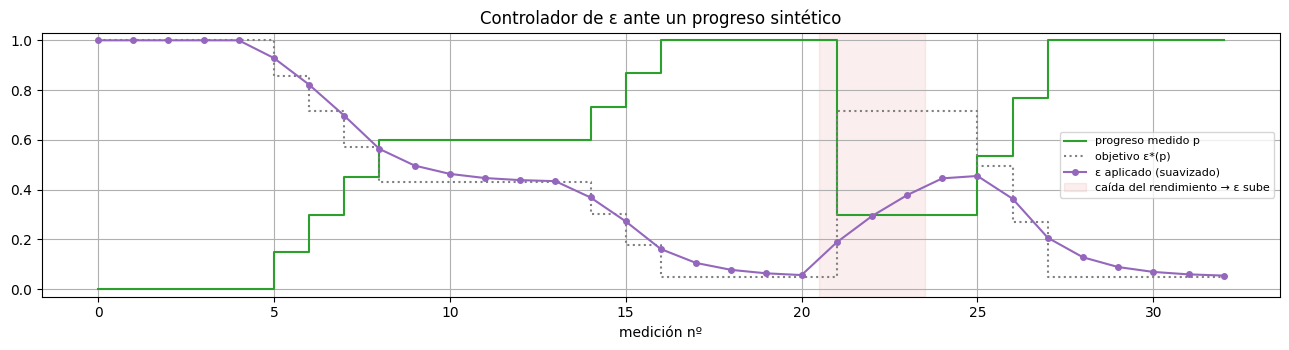

In [9]:
class AdaptiveEpsilon:
    """➕ Traduce el progreso medido (p ∈ [0, 1]) en un ε.

    objetivo     ε*(p) = ε_min + (ε_max − ε_min) · (1 − p)        (lineal en el PROGRESO, no en los episodios)
    suavizado    ε ← ε + β · (ε* − ε),   β = beta_down si ε* < ε (bajar)  ·  beta_up si ε* > ε (subir, más prudente)
    """

    def __init__(self, eps_max=1.0, eps_min=0.05, beta_down=0.5, beta_up=0.2):
        self.eps_max, self.eps_min = eps_max, eps_min
        self.beta_down, self.beta_up = beta_down, beta_up
        self.eps = eps_max

    def target(self, p):
        return self.eps_min + (self.eps_max - self.eps_min) * (1.0 - float(np.clip(p, 0, 1)))

    def update(self, p):
        tgt = self.target(p)
        beta = self.beta_down if tgt < self.eps else self.beta_up
        self.eps = float(np.clip(self.eps + beta * (tgt - self.eps), self.eps_min, self.eps_max))
        return self.eps


# ➕ Respuesta del controlador a una secuencia de progreso sintética (sin entrenar nada)
p_seq = np.r_[np.zeros(4), np.linspace(0, 0.6, 5), np.full(4, 0.6), np.linspace(0.6, 1, 4), np.full(4, 1.0),
              np.full(3, 0.3), np.linspace(0.3, 1, 4), np.full(5, 1.0)]
ctrl = AdaptiveEpsilon()
eps_seq = [ctrl.update(p) for p in p_seq]
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.step(range(len(p_seq)), p_seq, where="post", color="tab:green", label="progreso medido p")
ax.step(range(len(p_seq)), [AdaptiveEpsilon().target(p) for p in p_seq], where="post", color="gray", ls=":", label="objetivo ε*(p)")
ax.plot(eps_seq, "o-", color="tab:purple", ms=4, label="ε aplicado (suavizado)")
ax.axvspan(20.5, 23.5, color="tab:red", alpha=0.08, label="caída del rendimiento → ε sube")
ax.set_xlabel("medición nº"); ax.set_ylim(-0.03, 1.03); ax.grid(True); ax.legend(loc="center right", fontsize=8)
ax.set_title("Controlador de ε ante un progreso sintético"); plt.tight_layout(); plt.show()

**Lectura.** Mientras el progreso es 0, ε se queda en 1. Cuando el agente mejora, ε baja siguiendo al objetivo con un pequeño retraso, el que da el suavizado. En la meseta de 0.6 se estabiliza en ≈ 0.43 (= 0.05 + 0.95 · 0.4). Al llegar a p = 1 baja hasta ≈ 0.05. Cuando el progreso cae a 0.3 (zona sombreada), **ε vuelve a subir**, más despacio de lo que bajó, y cuando el agente se recupera vuelve a bajar.

### 3.4 El bucle de entrenamiento con el nuevo ε

> 🔧 **BLOQUE MODIFICADO** — `train_agent` del Ejercicio 2. El bucle (relleno del buffer con ε = 1 → `reset → act → step → experience → learn → update_target`) **no cambia**. Lo que cambia es la actualización de ε al final de cada episodio (`# 🔧`). Con `eps_schedule="adaptive"`, cada `eval_every` episodios se mide el progreso con `ProgressMonitor` y `AdaptiveEpsilon` fija el nuevo ε. Con `eps_schedule="linear"` se mantiene el decaimiento del Ejercicio 2 para poder comparar, y el progreso se mide igualmente, solo como diagnóstico. El historial registra el ε **usado** en cada episodio, el progreso y las métricas de control (`# ➕`). Se añaden `run_summary` y nuevos gráficos. `evaluate_agent` y `plot_gallery` son los del Ejercicio 2.

In [10]:
DEFAULT_CFG = dict(               # valores por defecto = los del Ejercicio 1
    nepisodes=300, epsilon=1.0, min_epsilon=0.05, gamma=0.99, alpha=1e-3, buffer_size=50_000,
    batch_size=64, hidden_neurons=32, learn_after=64, update_target_mult=10,    # update_target_after = mult * learn_after
    state_mode="schedule", seed=42,
    # ➕ Ejercicio 3: política de exploración
    eps_schedule="adaptive",      # "linear" = la del Ejercicio 2 (depende del nº de episodios) · "adaptive" = depende del progreso
    eval_every=10,                # cada cuántos episodios se MIDE el progreso (frecuencia de medida; no fija el valor de ε)
    n_control=8,                  # episodios de control de la medida de progreso
    beta_down=0.5, beta_up=0.2,   # suavizado del controlador (bajar / subir ε)
    p_cap_incomplete=0.8,         # progreso máximo de un episodio de control que no completa la orden
)

# ➕ Configuración final del Ejercicio 2 (§3.4 de su notebook): no se toca ningún hiperparámetro salvo la exploración
CFG_EJ2 = dict(nepisodes=200, gamma=0.95, alpha=1e-3, buffer_size=20_000, batch_size=64,
               hidden_neurons=32, learn_after=8, update_target_mult=10)


def train_agent(cfg, split="train", n_log=20, verbose=True):
    c = {**DEFAULT_CFG, **cfg}
    learn_after = c["learn_after"]
    update_target_after = c["update_target_mult"] * learn_after
    adaptive = c["eps_schedule"] == "adaptive"                                          # ➕
    epsilon_decay = (c["epsilon"] - c["min_epsilon"]) / (0.8 * c["nepisodes"])      # 🔧 solo se usa con el esquema lineal
    np.random.seed(c["seed"]); tf.random.set_seed(c["seed"])
    env = BestExecutionEnv(dict_[split], 60, state_mode=c["state_mode"])
    agent = FastDDQNAgent(env, gamma=c["gamma"], epsilon=c["epsilon"], alpha=c["alpha"], batch_size=c["batch_size"],
                          buffer_size=c["buffer_size"], hidden_neurons=c["hidden_neurons"])
    # ➕ Medida de progreso (también con el esquema lineal, solo como diagnóstico: allí no modifica ε)
    monitor = ProgressMonitor(dict_[split], n_control=c["n_control"], state_mode=c["state_mode"],
                              p_cap_incomplete=c["p_cap_incomplete"])
    eps_ctrl = AdaptiveEpsilon(c["epsilon"], c["min_epsilon"], c["beta_down"], c["beta_up"])     # ➕
    t0 = time.perf_counter()

    # (1) Relleno del buffer. En este punto epsilon es 1 -> actuando random
    s = env.reset()
    for _ in range(c["buffer_size"]):
        a = agent.act(s)
        s1, r, done, _ = env.step(a)
        agent.experience(s, a, r, s1, done)
        s = s1
        if done:
            s = env.reset()

    # (2) Entrenamiento
    agent.set_trainable(True)
    learn_counter, history = 0, []
    for episode in range(c["nepisodes"]):
        s = env.reset()
        step, cum_reward, ep_losses = 0, 0.0, []
        eps_used = agent.epsilon                                      # ➕ ε con el que se juega este episodio
        while True:
            a = agent.act(s)                                          # ε-greedy
            s1, r, done, _ = env.step(a)                              # el entorno evalúa la acción
            agent.experience(s, a, r, s1, done)                       # transición al buffer
            learn_counter += 1
            cum_reward += r
            s = s1
            step += 1
            if not learn_counter % learn_after:
                ep_losses.append(agent.learn())                       # un paso de gradiente con un batch del buffer
            if not learn_counter % update_target_after:
                agent.update_target()                                 # primary -> target
            if done:
                m = episode_metrics(env)
                m.update(episode=episode, ret=cum_reward, loss=np.mean(ep_losses) if ep_losses else np.nan, epsilon=eps_used)
                # 🔧 Actualización de ε
                if not adaptive:                                      # Ejercicio 2: depende del nº de episodios
                    agent.epsilon = max(agent.epsilon - epsilon_decay, c["min_epsilon"])
                if not (episode + 1) % c["eval_every"]:              # ➕ medida del progreso (greedy, episodios de control)
                    prog, ctrl_df = monitor.measure(agent)
                    if adaptive:                                      # ➕ Ejercicio 3: ε depende del progreso medido
                        agent.epsilon = eps_ctrl.update(prog)
                    m.update(progress=prog, ctrl_mae=ctrl_df.mae_pct.mean(),
                             ctrl_complete=(ctrl_df.exec_frac >= 1).mean() * 100, ctrl_ret=ctrl_df.sum_reward.mean())
                history.append(m)
                if verbose and not (episode + 1) % n_log:
                    h = pd.DataFrame(history[-n_log:])
                    print(f"Episode: {episode + 1:>3}, rew: {h.ret.mean():8.1f}, error calendario (train, con ε): {h.mae_pct.mean():5.2f}% | "
                          f"control greedy: progreso {h.progress.dropna().iloc[-1]:.2f}, error {h.ctrl_mae.dropna().iloc[-1]:5.2f}%, "
                          f"completas {h.ctrl_complete.dropna().iloc[-1]:3.0f}% | ε siguiente: {agent.epsilon:.3f}")
                break
    hist = pd.DataFrame(history)
    for col in ("progress", "ctrl_mae", "ctrl_complete", "ctrl_ret"):
        if col not in hist:
            hist[col] = np.nan
    return agent, hist, {"cfg": c, "seconds": time.perf_counter() - t0, "monitor": monitor}


def evaluate_agent(agent, split="val", n_episodes=N_EVAL, seed0=10_000):
    """Evaluación greedy (sin exploración ni aprendizaje) sobre episodios fijados por semilla."""
    eval_env = BestExecutionEnv(dict_[split], 60, state_mode=agent.env.state_mode)
    agent.set_trainable(False)
    agent.env = eval_env                       # el agente debe consultar el entorno que realmente ejecuta (ver Ejercicio 1)
    return evaluate(eval_env, agent.act, n_episodes=n_episodes, seed0=seed0)


def run_summary(hist, info):
    """➕ Resumen de un entrenamiento: cuándo alcanza el objetivo y cuánta exploración ha consumido."""
    meas = hist.dropna(subset=["progress"])
    ok = meas[(meas.ctrl_complete == 100) & (meas.ctrl_mae < 1.0)]
    low = hist.epsilon <= 0.10
    return {
        "1er episodio con objetivo cumplido (control)": int(ok.episode.iloc[0]) + 1 if len(ok) else np.nan,
        "1er episodio con ε ≤ 0.10": int(hist.episode[low].iloc[0]) + 1 if low.any() else np.nan,
        "acciones aleatorias (% de los steps)": float((hist.epsilon * hist.steps).sum() / hist.steps.sum() * 100),
        "progreso final (control)": float(meas.progress.iloc[-1]),
        "entrenamiento (s)": info["seconds"],
    }


def plot_training(hist, title="", others=None):
    """➕ Curvas del Ejercicio 3: ε frente al progreso, error greedy de control, retorno y pérdida.
    others: {nombre: hist} de otros entrenamientos para superponer (p. ej. el ε lineal)."""
    W = 15
    roll = lambda x: pd.Series(x).rolling(W, min_periods=1).mean()
    runs = {"adaptativo": hist, **(others or {})}
    styles = ["-", "--", ":"]
    fig, ax = plt.subplots(2, 2, figsize=(15, 8))
    for (name, h), ls in zip(runs.items(), styles):
        meas = h.dropna(subset=["progress"])
        ax[0, 0].plot(h.episode + 1, h.epsilon, color="tab:purple", ls=ls, label=f"ε · {name}")
        ax[0, 0].plot(meas.episode + 1, meas.progress, marker="o", color="tab:green", ms=3, ls=ls, lw=0.8, label=f"progreso p · {name}")
        ax[0, 1].plot(meas.episode + 1, meas.ctrl_mae, marker="o", color="tab:red", ms=3, ls=ls, lw=0.8, label=name)
        ax[1, 0].plot(h.episode + 1, roll(h.ret), color="tab:blue", ls=ls, label=name)
        ax[1, 1].plot(h.episode + 1, roll(h.loss), color="tab:brown", ls=ls, label=name)
    ax[0, 0].set_title("ε aplicado y progreso medido"); ax[0, 0].set_ylim(-0.03, 1.03)
    ax[0, 1].set_yscale("log"); ax[0, 1].axhline(1.0, color="k", ls=":", lw=1, label="objetivo < 1 %")
    ax[0, 1].axhline(0.5, color="gray", ls=":", lw=1, label="≈ mínimo teórico")
    ax[0, 1].set_title("Error de calendario greedy en los episodios de control (%, log)")
    ax[1, 0].set_title(f"Retorno por episodio de entrenamiento (con exploración, media móvil {W})")
    ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Pérdida (MSE real del batch, log)")
    for a_ in ax.ravel():
        a_.grid(True); a_.set_xlabel("episodio"); a_.legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(); plt.show()


def plot_gallery(env, named_policies, seeds):
    """Para cada semilla (= un episodio distinto): volumen acumulado (% de la orden) y desviación respecto al calendario."""
    fig, ax = plt.subplots(2, len(seeds), figsize=(5.2 * len(seeds), 7), squeeze=False)
    for j, seed in enumerate(seeds):
        for name, (pol, color) in named_policies.items():
            np.random.seed(seed)
            s, done = env.reset(), False
            while not done:
                s, r, done, _ = env.step(pol(s))
            B, C, n = env.episode_bins, env.vol_care, env.state_pos
            x = np.arange(1, n + 1) / B * 100
            ejec = np.cumsum(env.vol_hist)
            ax[0, j].step(x, ejec / C * 100, where="post", color=color, label=name, lw=1.4)
            ax[1, j].plot(x, ejec - C * np.arange(1, n + 1) / B, color=color, label=name, lw=0.9)
        ax[0, j].plot([0, 100], [0, 100], "k:", label="calendario lineal")
        ini = env.episode.index[0]
        ax[0, j].set_title(f"{ini:%Y-%m-%d %H:%M} · B={B}, C={C}", fontsize=10)
        ax[1, j].axhline(0, color="k", ls=":"); ax[1, j].set_xlabel("% del tiempo del episodio")
    ax[0, 0].set_ylabel("% de la orden ejecutado"); ax[1, 0].set_ylabel("desviación (títulos)")
    ax[0, 0].legend(fontsize=8); ax[1, 0].legend(fontsize=8)
    for a_ in ax.ravel():
        a_.grid(True)
    plt.tight_layout(); plt.show()

### 3.5 Entrenamiento con ε adaptativo

Configuración final del Ejercicio 2 (γ = 0.95, aprender cada 8 steps, buffer 20 000, α = 1e-3, 32 neuronas, **200 episodios**, semilla 42) con el nuevo ε. Para comparar, se entrena **también con el ε lineal** del Ejercicio 2, con la misma semilla. Como medir no altera la aleatoriedad, esta ejecución lineal es la misma que la del Ejercicio 2.

Los mensajes muestran cada 20 episodios: retorno y error de calendario de entrenamiento (con exploración), progreso, error y % de órdenes completas en los episodios de control (*greedy*) y el ε que se usará a continuación.

> ➕ **BLOQUE AÑADIDO** — entrenamientos con los dos esquemas y gráficos.

In [11]:
# ➕ Mismo problema, mismos hiperparámetros y misma semilla (42): solo cambia la política de exploración
print("=== ε ADAPTATIVO (Ejercicio 3) ===")
agent_a, hist_a, info_a = train_agent({**CFG_EJ2, "eps_schedule": "adaptive"})
print(f"Entrenamiento completado en {info_a['seconds']:.0f} s\n")
print("=== ε LINEAL (Ejercicio 2, referencia) ===")
agent_l, hist_l, info_l = train_agent({**CFG_EJ2, "eps_schedule": "linear"})
print(f"Entrenamiento completado en {info_l['seconds']:.0f} s")

=== ε ADAPTATIVO (Ejercicio 3) ===


Episode:  20, rew:  -1740.5, error calendario (train, con ε):  6.22% | control greedy: progreso 0.22, error  3.00%, completas   0% | ε siguiente: 0.860


Episode:  40, rew:   -581.0, error calendario (train, con ε):  2.65% | control greedy: progreso 0.72, error  1.18%, completas   0% | ε siguiente: 0.504


Episode:  60, rew:   -353.5, error calendario (train, con ε):  1.44% | control greedy: progreso 0.80, error  0.82%, completas   0% | ε siguiente: 0.315


Episode:  80, rew:   -246.6, error calendario (train, con ε):  0.97% | control greedy: progreso 1.00, error  0.62%, completas 100% | ε siguiente: 0.164


Episode: 100, rew:   -178.8, error calendario (train, con ε):  0.77% | control greedy: progreso 1.00, error  0.52%, completas 100% | ε siguiente: 0.090


... (11 outputs left out)

Episode: 140, rew:   -180.6, error calendario (train, con ε):  0.75% | control greedy: progreso 1.00, error  0.50%, completas 100% | ε siguiente: 0.169


Episode: 160, rew:   -142.1, error calendario (train, con ε):  0.68% | control greedy: progreso 1.00, error  0.49%, completas 100% | ε siguiente: 0.050


Episode: 180, rew:   -140.6, error calendario (train, con ε):  0.57% | control greedy: progreso 1.00, error  0.49%, completas 100% | ε siguiente: 0.050


Episode: 200, rew:   -132.8, error calendario (train, con ε):  0.56% | control greedy: progreso 1.00, error  0.49%, completas 100% | ε siguiente: 0.050
Entrenamiento completado en 180 s


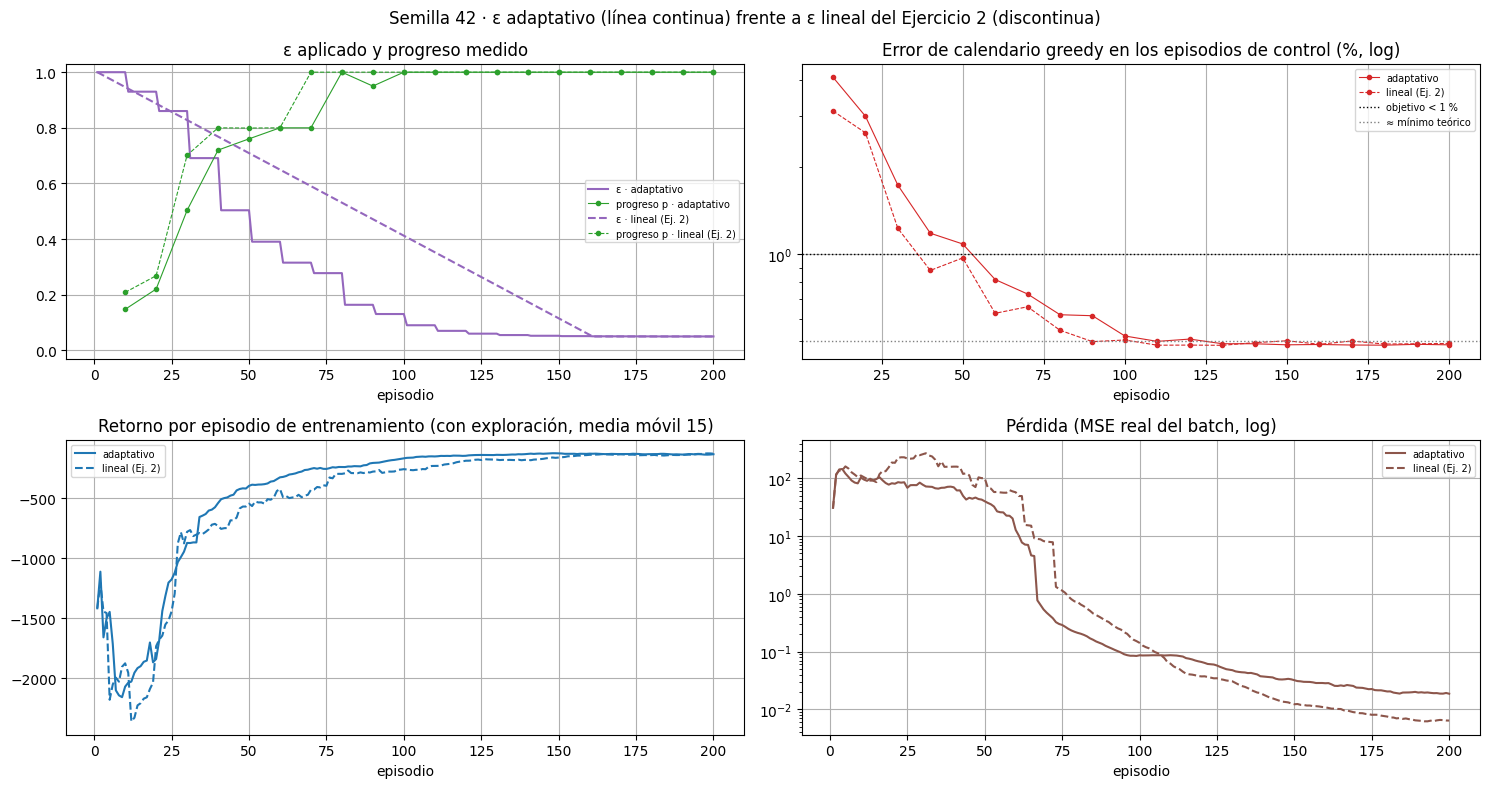

,ε adaptativo,ε lineal (Ej. 2)
1er episodio con objetivo cumplido (control),80.00,70.00
1er episodio con ε ≤ 0.10,101.00,153.00
acciones aleatorias (% de los steps),29.21,42.56
progreso final (control),1.00,1.00
entrenamiento (s),225.21,179.56


In [12]:
plot_training(hist_a, "Semilla 42 · ε adaptativo (línea continua) frente a ε lineal del Ejercicio 2 (discontinua)",
              others={"lineal (Ej. 2)": hist_l})
display(pd.DataFrame({"ε adaptativo": run_summary(hist_a, info_a), "ε lineal (Ej. 2)": run_summary(hist_l, info_l)}).round(2))

**Lectura de las curvas (semilla 42)**

* **ε sigue al aprendizaje, no al calendario de episodios** (panel superior izquierdo). El ε adaptativo baja a saltos cada vez que una medición muestra progreso. Pasa por 0.86 en el episodio 20 (p = 0.22), 0.50 en el 40 (p = 0.72) y 0.16 en el 80, y llega a ≤ 0.10 en el **episodio 101**. El lineal baja a ritmo fijo y no llega a 0.10 hasta el **153**, aunque el agente ya cumplía el objetivo en el 70–80.
* **La condición de completar la orden funciona como se diseñó.** Entre los episodios 40 y 70 el agente *greedy* ya sigue el calendario con un error < 1 % (0.82 % en el 60), pero **no completa ninguna orden de control**: le falta el último título. El progreso se queda en 0.8 (`p_cap`) y ε se mantiene en ≈ 0.3. Solo cuando el agente aprende a completar (episodio 80: 100 % de órdenes completas) el progreso sube a 1 y ε baja al mínimo. Sin esa condición, el agente habría dejado de explorar con una política que deja volumen pendiente.
* **El error de control** (panel superior derecho) baja en los dos casos al mínimo teórico (≈ 0.5 %) hacia el episodio 100. Los dos agentes acaban igual.
* **El retorno de entrenamiento** (panel inferior izquierdo) es mejor con el ε adaptativo desde el episodio 30, pero sobre todo porque **explora menos**: el retorno de entrenamiento mide agente *más* exploración (§3.2). Justo por eso no se usa para controlar ε.
* **Tabla:** con el mismo resultado final, el ε adaptativo toma **29 % de acciones aleatorias** frente al 43 % del lineal. El momento en que se cumple el objetivo es parecido (80 frente a 70). Con esta configuración, que ya está bien ajustada, el beneficio no es aprender antes, sino **no malgastar exploración** cuando el agente ya ha aprendido.

### 3.6 Comparación con el ε lineal: 3 semillas y datos de validación

Un entrenamiento de RL puede salir bien o mal por azar. Se repiten los dos esquemas con las semillas 1 y 2 (además de la 42) y se evalúan los seis agentes *greedy* sobre **100 episodios de *validation*** (2019, no vistos al entrenar; las mismas semillas de episodio que en §3.8 del Ejercicio 2). Además de los criterios C1–C3 se mide:

* **1er episodio con objetivo cumplido**: primera medición en la que el agente completa el 100 % de las órdenes de control con un error < 1 % (el criterio de «cumple» del Ejercicio 2).
* **Acciones aleatorias (% de los steps)**: el coste de la exploración, es decir, cuántas decisiones del entrenamiento se han tomado al azar.

*Tiempo de ejecución: unos 10 minutos.*

> ➕ **BLOQUE AÑADIDO** — comparación entre esquemas de exploración con varias semillas.

In [13]:
# ➕ Comparación con 3 semillas: entrenamiento con cada esquema y evaluación greedy sobre 100 episodios de VALIDATION
N_VAL = 100
runs = {("adaptativo", 42): (agent_a, hist_a, info_a), ("lineal (Ej. 2)", 42): (agent_l, hist_l, info_l)}
for sd in (1, 2):
    for sched, label in (("adaptive", "adaptativo"), ("linear", "lineal (Ej. 2)")):
        runs[(label, sd)] = train_agent({**CFG_EJ2, "eps_schedule": sched, "seed": sd}, verbose=False)
        print(f"{label:<15} semilla {sd}: {runs[(label, sd)][2]['seconds']:.0f} s")

cmp_rows = []
for (label, sd), (ag, h, inf) in runs.items():
    sm = summarize(evaluate_agent(ag, "val", n_episodes=N_VAL, seed0=30_000))
    cmp_rows.append({"esquema": label, "semilla": sd,
                     "C1 · órdenes completas (%)": sm["C1 · órdenes completas (%)"],
                     "C2 · tiempo usado (%)": sm["C2 · tiempo usado (% del episodio)"],
                     "C3 · error calendario (%)": sm["C3 · error de seguimiento (% de la orden)"],
                     "retorno medio": sm["retorno (suma de rewards) · media"],
                     **run_summary(h, inf)})
cmp_df = pd.DataFrame(cmp_rows).set_index(["esquema", "semilla"]).sort_index()
display(cmp_df.round(2))
display(cmp_df.groupby(level="esquema").agg(["mean", "std"]).T.round(2))

adaptativo      semilla 1: 295 s


lineal (Ej. 2)  semilla 1: 286 s


adaptativo      semilla 2: 216 s


lineal (Ej. 2)  semilla 2: 260 s


C1 · órdenes completas (%)  C2 · tiempo usado (%)  \
esquema        semilla                                                      
adaptativo     1                             100.0                  98.78   
               2                             100.0                  98.86   
               42                            100.0                  98.98   
lineal (Ej. 2) 1                             100.0                  99.00   
               2                             100.0                  98.89   
               42                            100.0                  98.68   

                        C3 · error calendario (%)  retorno medio  \
esquema        semilla                                             
adaptativo     1                             0.55        -130.08   
               2                             0.55        -128.60   
               42                            0.54        -126.90   
lineal (Ej. 2) 1                             0.54        -127.60   
               2                             0.55        -129.53   
               42                            0.55        -128.58   

                        1er episodio con objetivo cumplido (control)  \
esquema        semilla                                                 
adaptativo     1                                                  60   
               2                                                  80   
               42                                                 80   
lineal (Ej. 2) 1                                                 130   
               2                                                 100   
               42                                                 70   

                        1er episodio con ε ≤ 0.10  \
esquema        semilla                              
adaptativo     1                               91   
               2                              101   
               42                             101   
lineal (Ej. 2) 1                              153   
               2                              153   
               42                             153   

                        acciones aleatorias (% de los steps)  \
esquema        semilla                                         
adaptativo     1                                       25.96   
               2                                       26.22   
               42                                      29.21   
lineal (Ej. 2) 1                                       42.49   
               2                                       42.26   
               42                                      42.56   

                        progreso final (control)  entrenamiento (s)  
esquema        semilla                                               
adaptativo     1                             1.0             295.49  
               2                             1.0             216.18  
               42                            1.0             225.21  
lineal (Ej. 2) 1                             1.0             286.26  
               2                             1.0             259.52  
               42                            1.0             179.56

esquema                                            adaptativo  lineal (Ej. 2)
C1 · órdenes completas (%)                   mean      100.00          100.00
                                             std         0.00            0.00
C2 · tiempo usado (%)                        mean       98.87           98.85
                                             std         0.10            0.16
C3 · error calendario (%)                    mean        0.55            0.55
                                             std         0.01            0.00
retorno medio                                mean     -128.53         -128.57
                                             std         1.59            0.97
1er episodio con objetivo cumplido (control) mean       73.33          100.00
                                             std        11.55           30.00
1er episodio con ε ≤ 0.10                    mean       97.67          153.00
                                             std         5.77            0.00
acciones aleatorias (% de los steps)         mean       27.13           42.44
                                             std         1.80            0.16
progreso final (control)                     mean        1.00            1.00
                                             std         0.00            0.00
entrenamiento (s)                            mean      245.63          241.78
                                             std        43.42           55.52

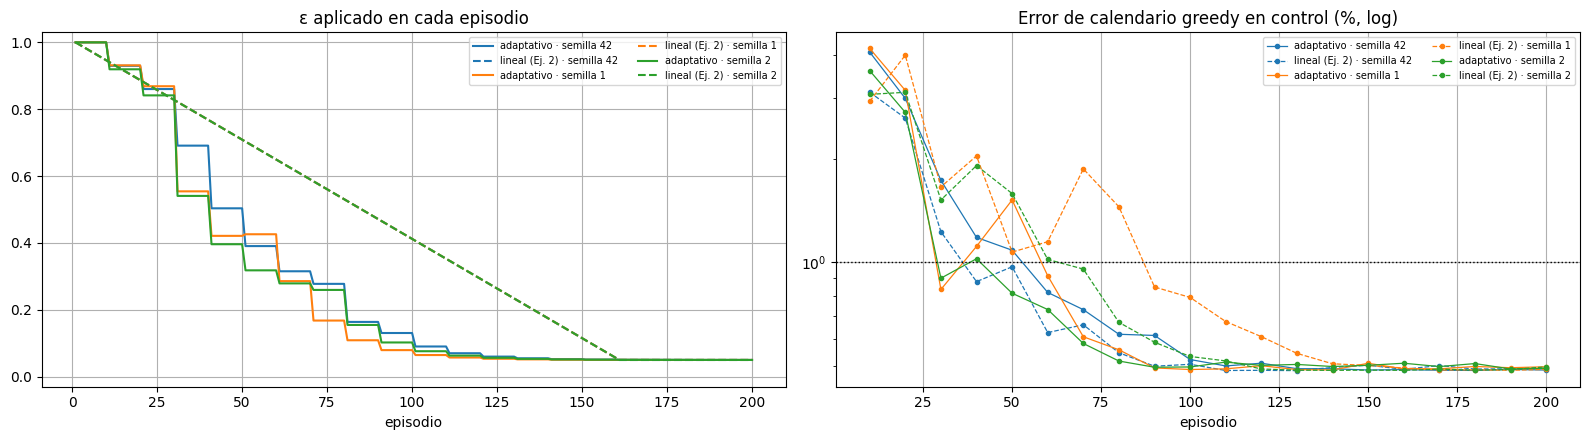

In [14]:
# ➕ ε y error greedy de control de las 6 ejecuciones (3 semillas × 2 esquemas)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
colors = {42: "tab:blue", 1: "tab:orange", 2: "tab:green"}
for (label, sd), (ag, h, inf) in runs.items():
    ls = "-" if label == "adaptativo" else "--"
    meas = h.dropna(subset=["progress"])
    ax[0].plot(h.episode + 1, h.epsilon, color=colors[sd], ls=ls, label=f"{label} · semilla {sd}")
    ax[1].plot(meas.episode + 1, meas.ctrl_mae, color=colors[sd], ls=ls, marker="o", ms=3, lw=0.9, label=f"{label} · semilla {sd}")
ax[0].set_title("ε aplicado en cada episodio"); ax[0].set_ylim(-0.03, 1.03)
ax[1].set_yscale("log"); ax[1].axhline(1.0, color="k", ls=":", lw=1); ax[1].set_title("Error de calendario greedy en control (%, log)")
for a_ in ax:
    a_.grid(True); a_.set_xlabel("episodio"); a_.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**Lectura de la comparación (3 semillas, 100 episodios de *validation*)**

* **Mismo resultado final.** Los seis agentes completan el **100 %** de las órdenes con un error de calendario de **0.54–0.55 %** (mínimo teórico ≈ 0.5 %) y el mismo retorno (−128.5 ± 1.6 frente a −128.6 ± 1.0). Era lo esperable: con 200 episodios y una buena configuración, los dos esquemas tienen tiempo de sobra para converger. **Cambiar la exploración no empeora el agente.**
* **La exploración se adapta al agente.** El ε adaptativo llega a ≤ 0.10 en el episodio **98 ± 6** y el lineal siempre en el **153**, porque solo depende del número de episodios. En total, el adaptativo toma un **27 %** de acciones aleatorias y el lineal un **42 %**: un tercio menos de exploración para el mismo resultado.
* **Se alcanza antes el objetivo, de media:** episodio 73 ± 12 frente a 100 ± 30. La semilla 1 lo ilustra: con el ε lineal el agente tarda hasta el episodio 130, y su curva naranja discontinua del gráfico de la derecha tiene un pico de error hacia el episodio 70 que el lineal no puede compensar. Con el adaptativo se cumple en el 60. Con tres semillas por esquema esta diferencia es indicativa, no concluyente: la semilla 42 lo cumple antes con el lineal (70 frente a 80).
* **Las curvas de ε del gráfico** son distintas en cada semilla para el adaptativo (cada agente aprende a su ritmo) y **idénticas** para el lineal. Es justo lo que pide el enunciado: que ε no dependa del número de episodios.

### 3.7 Prueba de estrés: ¿qué pasa cuando el agente no aprende?

La propiedad más importante de un ε ligado al aprendizaje es que **no deja de explorar si el agente no ha aprendido**. Para comprobarlo se usan los hiperparámetros del Ejercicio 1 (γ = 0.99, aprender cada 64 steps, buffer de 50 000, 300 episodios), con los que el Ejercicio 2 (§2.6) mostró que el agente **no converge**, y se entrena con los dos esquemas.

> ➕ **BLOQUE AÑADIDO** — entrenamiento con una configuración mala, con los dos esquemas de exploración.

adaptativo     : 230 s


lineal (Ej. 2) : 72 s


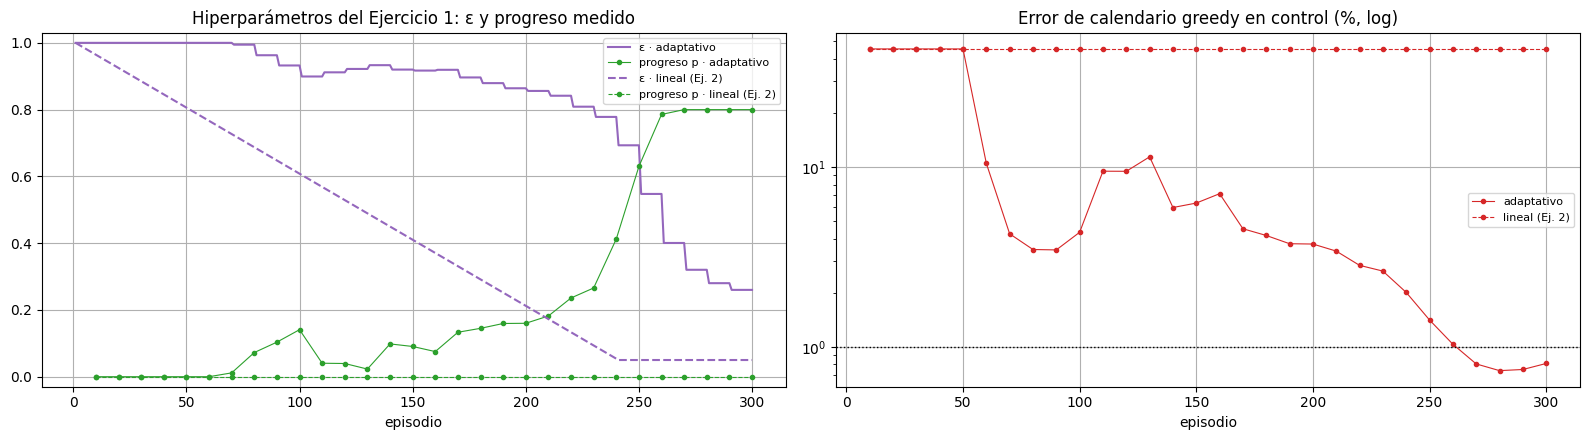

,adaptativo,lineal (Ej. 2)
C1 · órdenes completas (%),0.00,100.00
C3 · error calendario (%),0.89,46.00
retorno medio,-210.51,-11050.76
ε final,0.26,0.05
1er episodio con objetivo cumplido (control),NaN,NaN
1er episodio con ε ≤ 0.10,NaN,229.00
acciones aleatorias (% de los steps),81.50,63.51
progreso final (control),0.80,0.00
entrenamiento (s),229.90,71.94


In [15]:
# ➕ Prueba de estrés: la configuración del Ejercicio 1, con la que el Ejercicio 2 mostró que el agente NO aprende
CFG_EJ1 = dict(nepisodes=300, gamma=0.99, alpha=1e-3, buffer_size=50_000, batch_size=64,
               hidden_neurons=32, learn_after=64, update_target_mult=10)
stress = {}
for sched, label in (("adaptive", "adaptativo"), ("linear", "lineal (Ej. 2)")):
    stress[label] = train_agent({**CFG_EJ1, "eps_schedule": sched}, verbose=False)
    print(f"{label:<15}: {stress[label][2]['seconds']:.0f} s")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for label, (ag, h, inf) in stress.items():
    ls = "-" if label == "adaptativo" else "--"
    meas = h.dropna(subset=["progress"])
    ax[0].plot(h.episode + 1, h.epsilon, color="tab:purple", ls=ls, label=f"ε · {label}")
    ax[0].plot(meas.episode + 1, meas.progress, color="tab:green", ls=ls, marker="o", ms=3, lw=0.8, label=f"progreso p · {label}")
    ax[1].plot(meas.episode + 1, meas.ctrl_mae, color="tab:red", ls=ls, marker="o", ms=3, lw=0.8, label=label)
ax[0].set_title("Hiperparámetros del Ejercicio 1: ε y progreso medido"); ax[0].set_ylim(-0.03, 1.03)
ax[1].set_yscale("log"); ax[1].axhline(1.0, color="k", ls=":", lw=1); ax[1].set_title("Error de calendario greedy en control (%, log)")
for a_ in ax:
    a_.grid(True); a_.set_xlabel("episodio"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

stress_rows = {}
for label, (ag, h, inf) in stress.items():
    sm = summarize(evaluate_agent(ag, "val", n_episodes=N_VAL, seed0=30_000))
    stress_rows[label] = {"C1 · órdenes completas (%)": sm["C1 · órdenes completas (%)"],
                          "C3 · error calendario (%)": sm["C3 · error de seguimiento (% de la orden)"],
                          "retorno medio": sm["retorno (suma de rewards) · media"],
                          "ε final": h.epsilon.iloc[-1], **run_summary(h, inf)}
display(pd.DataFrame(stress_rows).round(2))

**Lectura de la prueba de estrés.** Es el resultado más claro del ejercicio.

* **ε lineal:** baja a 0.05 en el episodio 240 **aunque el progreso es 0 en todas las mediciones**. El agente *greedy* compra de golpe durante todo el entrenamiento (error del 46 %), y al final explota justo esa política. En *validation* completa el 100 % de las órdenes, pero en el primer 10 % del tiempo, con un error de calendario del **46 %** y un retorno de **−11 051** (peor que el azar). Es el fallo que ya diagnosticó el Ejercicio 2 (§2.6).
* **ε adaptativo:** como el progreso es 0, **ε se queda en 1 durante los primeros 70 episodios**. El agente sigue llenando el buffer con experiencia diversa y aprende de ella, porque DQN es *off-policy* y puede aprender de las acciones aleatorias. Hacia el episodio 60 el error de control baja del 45 % al ≈ 4 %. ε empieza a bajar a medida que el progreso sube y **vuelve a subir algo** (0.90 → 0.93, episodios 100–130) cuando el progreso cae de 0.14 a 0.02: es la parte «al alza» del controlador. Al final, el agente sigue el calendario con un **error del 0.89 %** en *validation* (retorno −211, al nivel del TWAP).
* **Pero no completa las órdenes** (C1 = 0 %): le falta el último título, el mismo patrón que el Ejercicio 2 encontró con configuraciones «casi buenas». La medida lo detecta: el progreso se queda en 0.8 (`p_cap`) y **ε no baja de 0.26**. El controlador está diciendo correctamente que el agente aún no ha terminado de aprender. Con más episodios seguiría explorando hasta conseguirlo, y por eso la duración del entrenamiento debería depender del aprendizaje (Ejercicio 4, Idea C).
* **Conclusión:** con una configuración que aprende despacio, el ε lineal **condena** al agente a la mala política que tenga en el episodio 240. El ε adaptativo mantiene la exploración mientras haga falta, y con los mismos hiperparámetros malos pasa de un error del 46 % a uno del 0.9 %. Es la diferencia entre un ε que depende del número de episodios y uno que depende del aprendizaje.

### 3.8 Resultados en *train*: imágenes del agente entrenado con ε adaptativo

Se comprueba que el agente entrenado con el nuevo esquema de exploración sigue replicando un TWAP (el objetivo del Ejercicio 2). Se usa la figura estándar del repositorio, del mismo tipo que la imagen de referencia del enunciado, y la comparación con el TWAP y el calendario lineal en tres episodios con distinto día, hora, duración y tamaño de orden.

> ➕ **BLOQUE AÑADIDO** — gráficos en *train* con el agente final (ε adaptativo, semilla 42).

seed 10001: 2018-03-22 14:35 · B = 447, C = 36 · ejecutado 100% en 98.7% del tiempo · error de calendario 0.72%


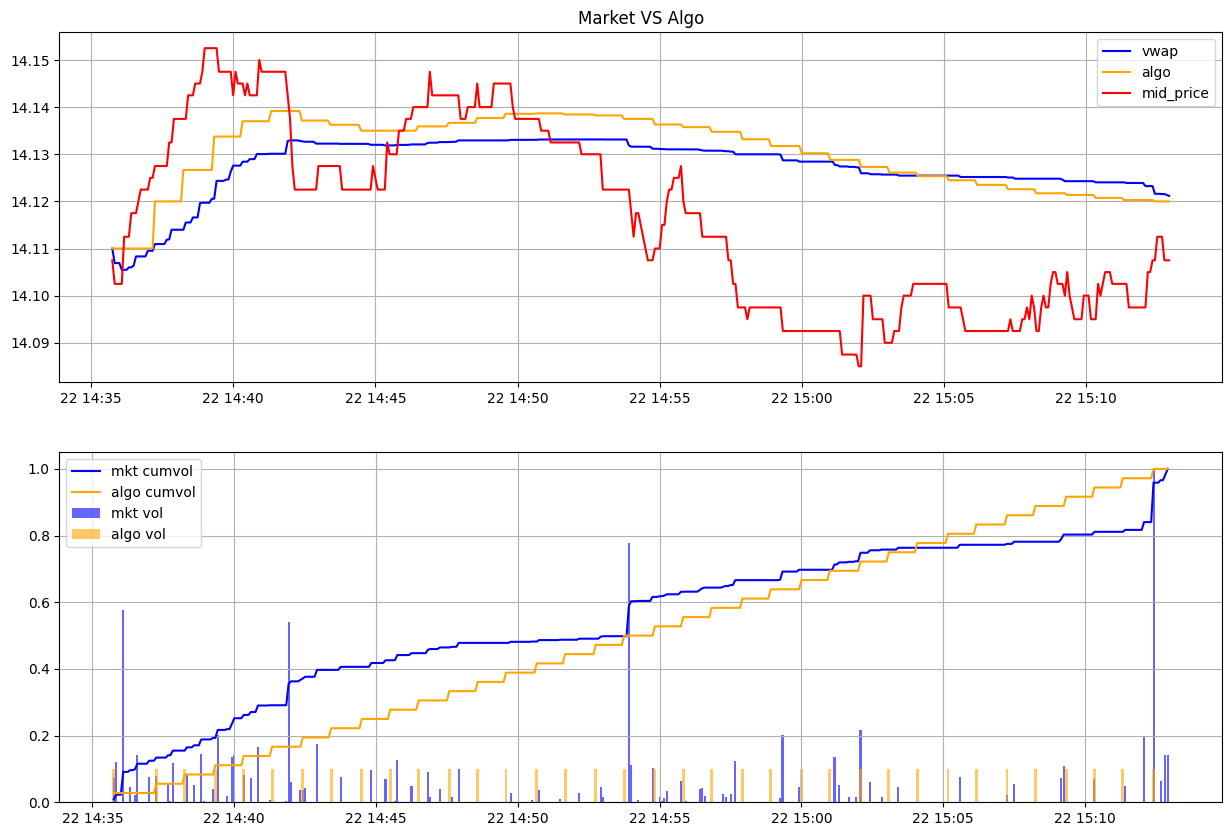

seed 10007: 2018-01-24 16:13 · B = 594, C = 65 · ejecutado 100% en 99.3% del tiempo · error de calendario 0.39%


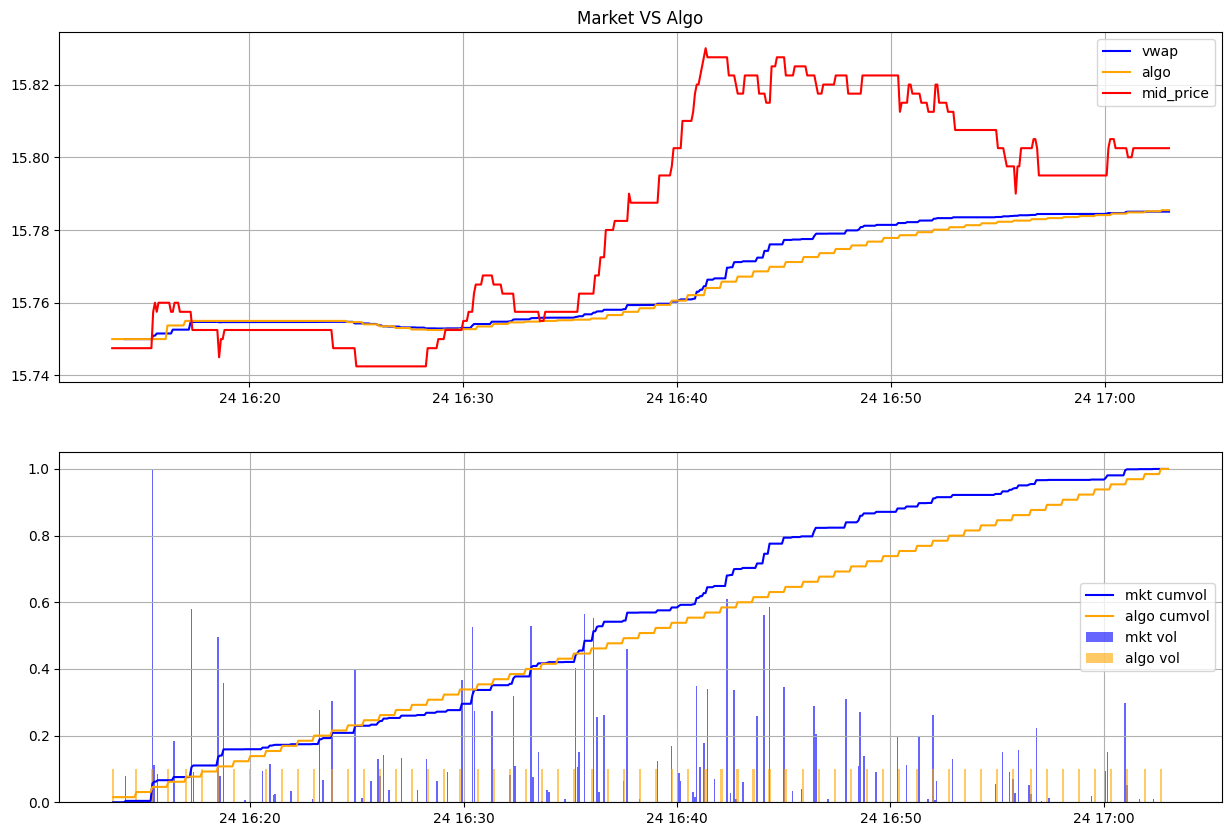

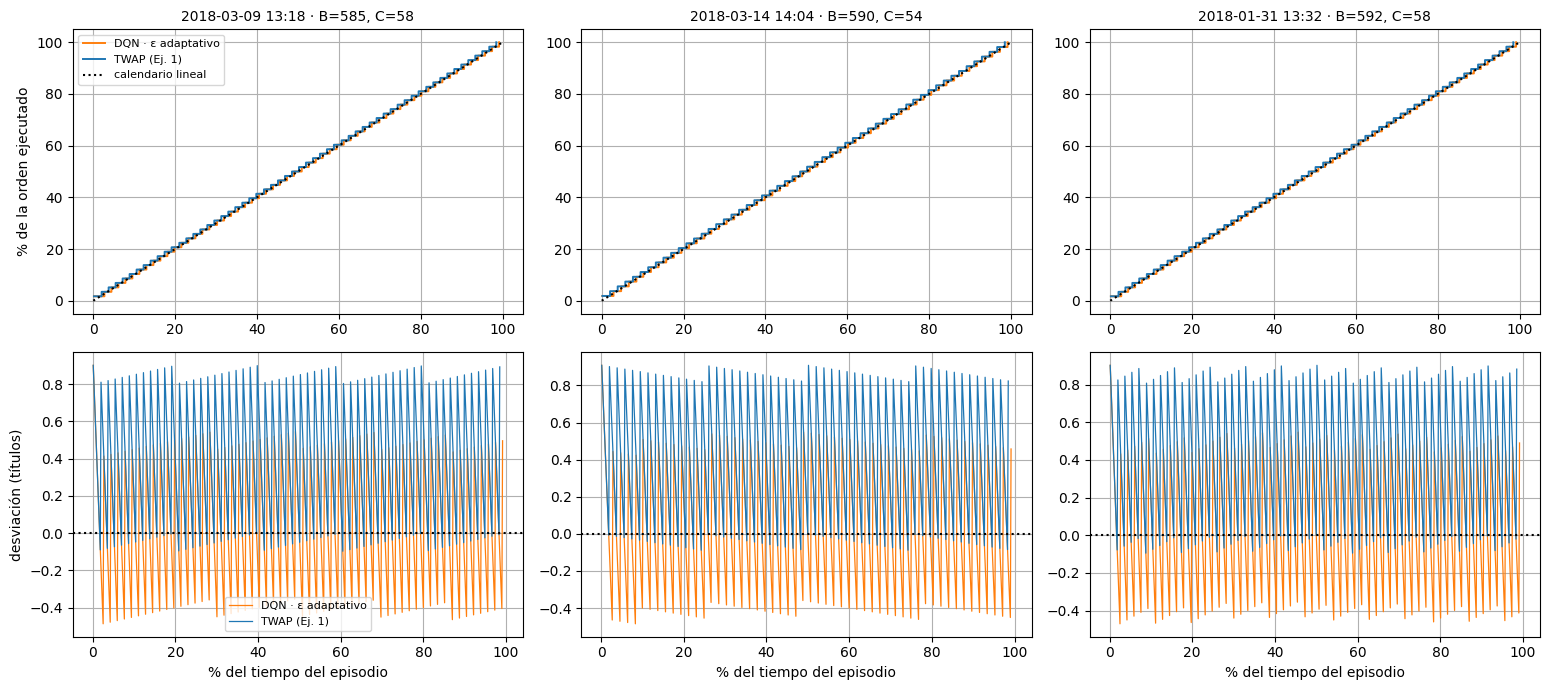

In [16]:
# ➕ El agente entrenado con ε adaptativo (semilla 42) en episodios de train: figura estándar del repositorio
img_env = BestExecutionEnv(dict_["train"], 60)
agent_a.set_trainable(False); agent_a.env = img_env
for seed in (10_001, 10_007):
    np.random.seed(seed)
    s, done = img_env.reset(), False
    while not done:
        s, r, done, _ = img_env.step(agent_a.act(s))
    m = episode_metrics(img_env)
    print(f"seed {seed}: {img_env.episode.index[0]:%Y-%m-%d %H:%M} · B = {m['bins']}, C = {m['vol_care']} · "
          f"ejecutado {m['exec_frac'] * 100:.0f}% en {m['time_frac'] * 100:.1f}% del tiempo · error de calendario {m['mae_pct']:.2f}%")
    plot_results(img_env); plt.show()

env_g = BestExecutionEnv(dict_["train"], 60)
agent_a.env = env_g
plot_gallery(env_g, {"DQN · ε adaptativo": (agent_a.act, "tab:orange"), "TWAP (Ej. 1)": (TWAP(env_g).act, "tab:blue")},
             seeds=[20_002, 20_005, 20_011])

**Lectura de las imágenes.** El agente entrenado con el ε adaptativo sigue siendo un TWAP, como el del Ejercicio 2:

* **Figuras `plot_results`:** el volumen acumulado del algoritmo (naranja, panel inferior) es una escalera regular de 0 % a 100 % que termina al final del episodio. Es independiente de cuándo negocia el mercado, que avanza a saltos (azul). El VWAP del algoritmo acompaña al del mercado sin intentar batirlo. Los dos episodios completan la orden en el 98.7–99.3 % del tiempo, con errores de calendario del 0.72 % (`C` = 36) y 0.39 % (`C` = 65).
* **Galería:** en tres episodios con otro día, hora, duración y tamaño, la desviación del agente oscila entre −0.45 y +0.5 títulos, **centrada en el calendario**, como la regla óptima. La del TWAP del Ejercicio 1 va siempre por delante (0 a +0.9). Es el mismo comportamiento que obtuvo el agente del Ejercicio 2: cambiar la exploración no ha cambiado lo que se aprende, solo **cuánto se explora para aprenderlo**.

---
## 4. Conclusiones

### Respuesta a las dos preguntas del enunciado

**¿Cómo determinamos que el algoritmo ha mejorado?** Con el **rendimiento de su política *greedy*** en un conjunto fijo de episodios de control, comparado con un ***baseline*** (la política aleatoria, que es lo que hace el agente cuando explora) y un ***benchmark*** que hace de nivel de aspiración (el TWAP clásico, el algoritmo sin ML que se quiere igualar). El coste se normaliza por episodio y en escala logarítmica, y se exige además completar la orden. La medida se verificó antes de entrenar: ordena correctamente las cinco políticas de referencia, incluido el óptimo, que no participa en su construcción, y no altera el entrenamiento.

**¿Cómo trasladamos esta mejora a ε?** Con un **objetivo lineal en el progreso**, `ε* = ε_min + (ε_max − ε_min)(1 − p)`, y un **suavizado asimétrico** que filtra el ruido de las mediciones y permite que ε **vuelva a subir** si el agente empeora. El número de episodios solo fija cada cuánto se mide, no el valor de ε.

### Qué dicen los resultados

1. **Con una buena configuración, el agente final es el mismo** (100 % de órdenes completas, error del 0.55 %, 3 semillas, *validation*), pero con **un tercio menos de exploración** (27 % frente a 42 % de acciones aleatorias). La exploración se retira cuando el agente ha aprendido, en el episodio ≈ 98, y no cuando lo marca el calendario (153).
2. **Con una mala configuración, el ε adaptativo marca la diferencia.** El lineal deja de explorar con un agente que compra de golpe (error del 46 %). El adaptativo mantiene la exploración mientras no hay progreso y el agente llega a un error del 0.89 %.
3. **La medida detecta lo que el retorno no ve.** Por dos veces (§3.5 y §3.7) el agente seguía bien el calendario pero dejaba el último título sin comprar. La condición de completar la orden mantuvo ε alto justo en ese momento.
4. **El retorno de entrenamiento no sirve para controlar ε**, porque está contaminado por la propia exploración (§3.5). Hay que medir la política *greedy*.

### Limitaciones

* **Coste de medir:** cada medición son 8 episodios sin aprendizaje (≈ 10–15 % más de tiempo de entrenamiento). Con más episodios de control la medida sería menos ruidosa pero más cara.
* **Parámetros del controlador** (`eval_every`, `n_control`, β, `p_cap`) elegidos con criterio y no ajustados. No se ha estudiado su sensibilidad.
* **Depende de tener un *benchmark*.** Aquí el TWAP es natural. En otros problemas el nivel de aspiración puede no ser obvio, y si es demasiado fácil de alcanzar la exploración se retira antes de tiempo.
* **Solo rendimiento, no cobertura del espacio.** Es suficiente aquí porque el espacio de estados es pequeño (§3.2). Con un estado más rico (Ejercicio 4, Idea A) convendría combinar la medida con una de cobertura.
* **Número fijo de episodios**, como permite el enunciado. La prueba de estrés muestra que, con una mala configuración, 300 episodios no bastan para completar el aprendizaje.

### Siguientes pasos (Ejercicio 4, Idea C)

La medida de progreso de este ejercicio es la pieza que necesita la **parada del entrenamiento por aprendizaje**. Se puede parar cuando `p = 1` y el error de control lleve varias mediciones sin mejorar, guardar *checkpoints* del mejor agente según esa misma medida y recuperarlo si el entrenamiento se degrada. Así la duración del entrenamiento también quedaría condicionada a la evolución del aprendizaje, como pide el enunciado.